# Contact prediction in stationary and moving environments

This notebook follows the existing contact experiments from their physical interpretation to prediction error, reference methods and one moving posterior. It reads the original saved measurements and posterior parameters. Model settings, selected estimator parameters and simulation identifiers are unchanged.

The stationary concentrated-input history below uses the controlled `static_concentrated` fixture: both the physical plane and the sensor frame are fixed. It is distinct from the saved `plane` transport experiment, where the plane is fixed in world coordinates and the sensor rotates. In that experiment, the measured $G_t$ describes only the sensor-coordinate change.

Let $R_t$ map sensor coordinates to world coordinates. Then
$P_t^{\mathrm{sensor}}=R_t^\top P_t^{\mathrm{world}}R_t$ and $G_t=R_t^\top R_{t-1}$.

For the sphere, the physical tangent plane changes as the contact point moves, and the sensor frame also rotates. The measured $G_t$ still accounts only for sensor-frame rotation. It does not supply the changing physical tangent plane to the tracker.

The application is the maintained bilateral contact model already used in the original notebook. These diagnostics do not introduce another physical plane model, friction model or unilateral contact rule.

In [1]:
from pathlib import Path
import os
import sys
ROOT = Path.cwd() if (Path.cwd() / 'lib').exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT))
LOCAL_TEX = Path('/workspace/.local/tex')
if (LOCAL_TEX / 'usr/bin/dvipng').exists():
    os.environ['PATH'] = str(LOCAL_TEX / 'usr/bin') + os.pathsep + os.environ['PATH']
    os.environ.setdefault('TEXMFHOME', str(LOCAL_TEX / 'usr/share/texmf'))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import colors
from matplotlib.lines import Line2D
from IPython import get_ipython
from IPython.display import Markdown, display
from lib.contact_prediction_diagnostics import load_contact_prediction_diagnostics
from lib.contact_moving_snapshot import load_moving_sphere_snapshot

# Data readers validate the saved experiment; neither reruns the estimator.
data = load_contact_prediction_diagnostics(ROOT)
snapshot = load_moving_sphere_snapshot(ROOT, t=96)
EDITABLE_OUTPUT = ROOT / 'results/contact_prediction_diagnostics/figures'
if get_ipython() is not None:
    get_ipython().run_line_magic('matplotlib', 'inline')
    get_ipython().run_line_magic('config', "InlineBackend.figure_format = 'png'")
    get_ipython().run_line_magic('config', "InlineBackend.print_figure_kwargs = {'bbox_inches': None}")
plt.rcParams.update({
    'text.usetex': True,
    'text.latex.preamble': r'\usepackage{amsmath}\usepackage{amssymb}',
    'font.family': 'serif', 'lines.linewidth': 1.8, 'lines.markersize': 5,
    'savefig.bbox': None, 'figure.max_open_warning': 0,
})
print('Saved contact predictions and the corrected sphere posterior at t=96 are verified.')


Saved contact predictions and the corrected sphere posterior at t=96 are verified.


## Prediction error

The saved clean-velocity error is
\[
\mathcal E_t(D_t)=\frac13\sum_{j=1}^{3}\|D_t v_t^{(j)}-P_{\mathcal X_t}v_t^{(j)}\|^2,
\qquad v_t^{(j)}=v_0 R_t^\top e_j,\quad v_0=0.02\,\mathrm{m/s}.
\]
The squared norm sums the velocity coordinates; there is no second division by three. Multiplication by $10^6$ converts the saved SI errors to $(\mathrm{mm}/\mathrm{s})^2$.

The posterior-mean response uses $D_t=\overline P_t^+$, the mode uses $P_{\widehat{\mathcal X}_t}$, and the isotropic comparison uses $\overline P_t^{\mathrm{iso}}$. Each point is a Monte Carlo mean over the same 256 simulations. Blue shading is a pointwise Student 95% confidence interval for that mean. It is not posterior uncertainty about the error of one simulation.

### Stationary plane with concentrated inputs

Both the plane and sensor frame remain fixed in this controlled fixture. Concentrated applied inputs reveal some normal rotations more clearly than others. Only the saved checkpoints $t=1,4,16,32$ are shown. Differences among these actions test the value of the posterior mean for predicting clean velocities under this observation model.

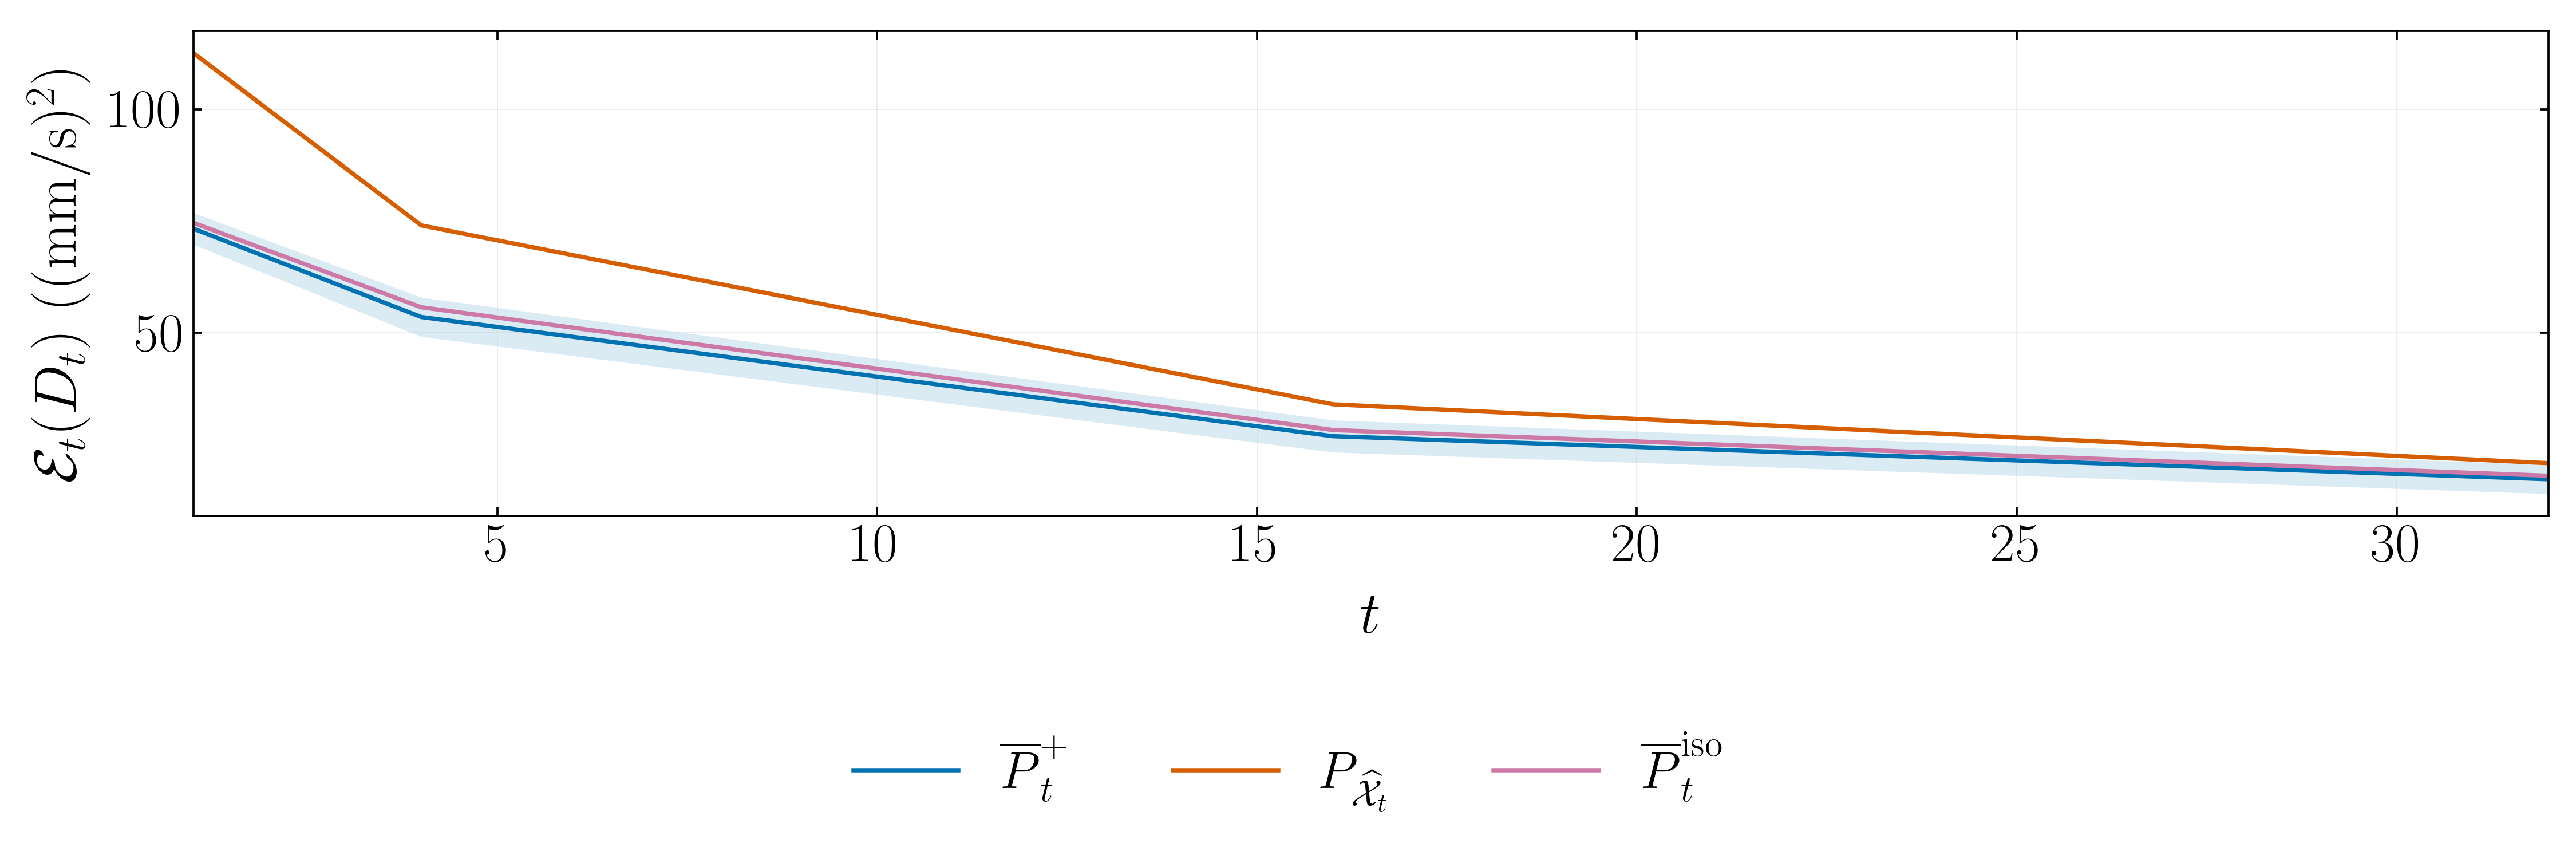

In [5]:
# Edit this figure's canvas, text, colors and save commands directly.
DPI = 300
FIGSIZE = (15, 5)
LABEL_FONT_SIZE = 25.
TICK_FONT_SIZE = 23.
LEGEND_FONT_SIZE = 22.
plt.rcParams.update({
    'text.usetex': True, 'font.family': 'serif', 'font.size': LABEL_FONT_SIZE,
    'axes.labelsize': LABEL_FONT_SIZE, 'axes.titlesize': LABEL_FONT_SIZE,
    'xtick.labelsize': TICK_FONT_SIZE, 'ytick.labelsize': TICK_FONT_SIZE,
    'legend.fontsize': LEGEND_FONT_SIZE, 'axes.labelpad': 8.,
    'figure.dpi': DPI, 'savefig.dpi': DPI,
})
SAVE_PDF = True
PDF_PATH = EDITABLE_OUTPUT / 'prediction_error_stationary.pdf'
DRAFT_SECTION = 'main'
DRAFT_PATH = ROOT / 'results' / DRAFT_SECTION / 'contact' / PDF_PATH.name

LABELS = {
    'mean': r'$\overline P_t^+$', 'mode': r'$P_{\widehat{\mathcal X}_t}$',
    'iso': r'$\overline P_t^{\mathrm{iso}}$',
    'regularized': r'$\widetilde M_t$',
    'great_window': 'GREAT (sliding window)', 'great_ew': 'GREAT (exponential weighting)',
}
COLORS = {'mean':'#0072B2', 'mode':'#D55E00', 'iso':'#CC79A7',
          'regularized':'#8C564B', 'great_window':'#009E73', 'great_ew':'#56B4E9'}

condition = 'static_concentrated'
record = data['conditions'][condition]
fig, ax = plt.subplots(figsize=FIGSIZE, dpi=DPI, layout='constrained')
for curve in record['curves']:
    method = curve['method']
    points = np.asarray(curve['points'], dtype=float)
    ax.plot(points[:, 0], points[:, 1], color=COLORS[method], label=LABELS[method], linestyle='-')
    if method == 'mean':
        ax.fill_between(points[:,0], points[:,2], points[:,3],
                        color=COLORS[method], alpha=.14, linewidth=0)
ax.set(xlabel=r'$t$', ylabel=r'$\mathcal E_t(D_t)$ $((\mathrm{mm}/\mathrm{s})^2)$',
       xlim=(1, int(record['T'])))
BORDER_WIDTH = .9
for spine in ax.spines.values():
    spine.set_visible(True)
    spine.set_linewidth(BORDER_WIDTH)
ax.tick_params(axis='both', which='both', direction='in',
               top=True, right=True, bottom=True, left=True,
               labeltop=False, labelright=False, labelbottom=True, labelleft=True,
               width=BORDER_WIDTH)
ax.xaxis.set_label_position('bottom')
ax.yaxis.set_label_position('left')
ax.grid(color='#BFC4C8', alpha=.30, linewidth=.45)
fig.legend(*ax.get_legend_handles_labels(), loc='outside lower center',
           ncol=3, frameon=False, fontsize=LEGEND_FONT_SIZE)

# Vector text/curves remain in the PDF; surfaces are rasterized at DPI.
fig.get_layout_engine().set(h_pad=.18, w_pad=.16)
if SAVE_PDF:
    PDF_PATH.parent.mkdir(parents=True, exist_ok=True)
    fig.savefig(PDF_PATH, dpi=DPI, bbox_inches=None)
    PNG_PATH = PDF_PATH.with_suffix('.png')
    fig.savefig(PNG_PATH, dpi=DPI, bbox_inches=None)
    DRAFT_PATH.parent.mkdir(parents=True, exist_ok=True)
    DRAFT_PATH.write_bytes(PDF_PATH.read_bytes())
    DRAFT_PNG_PATH = DRAFT_PATH.with_suffix('.png')
    DRAFT_PNG_PATH.write_bytes(PNG_PATH.read_bytes())
plt.show()


### Contact moving over a sphere

Here the physical tangent plane moves as well as changing coordinates with the sensor. The history uses all 48 original action times $t=4,8,\ldots,192$, recovered by a verified deterministic replay of the same 256 simulations. Lines join these recorded action errors without interpolation or an assumed event at $t=128$. The test reveals tracking performance under the already selected estimator settings, including any effects of physical motion not represented by measured frame transport. The gray control uses the saved posterior-mean predictions with $G_t=I_3$, omitting measured sensor-frame transport while retaining its original settings.

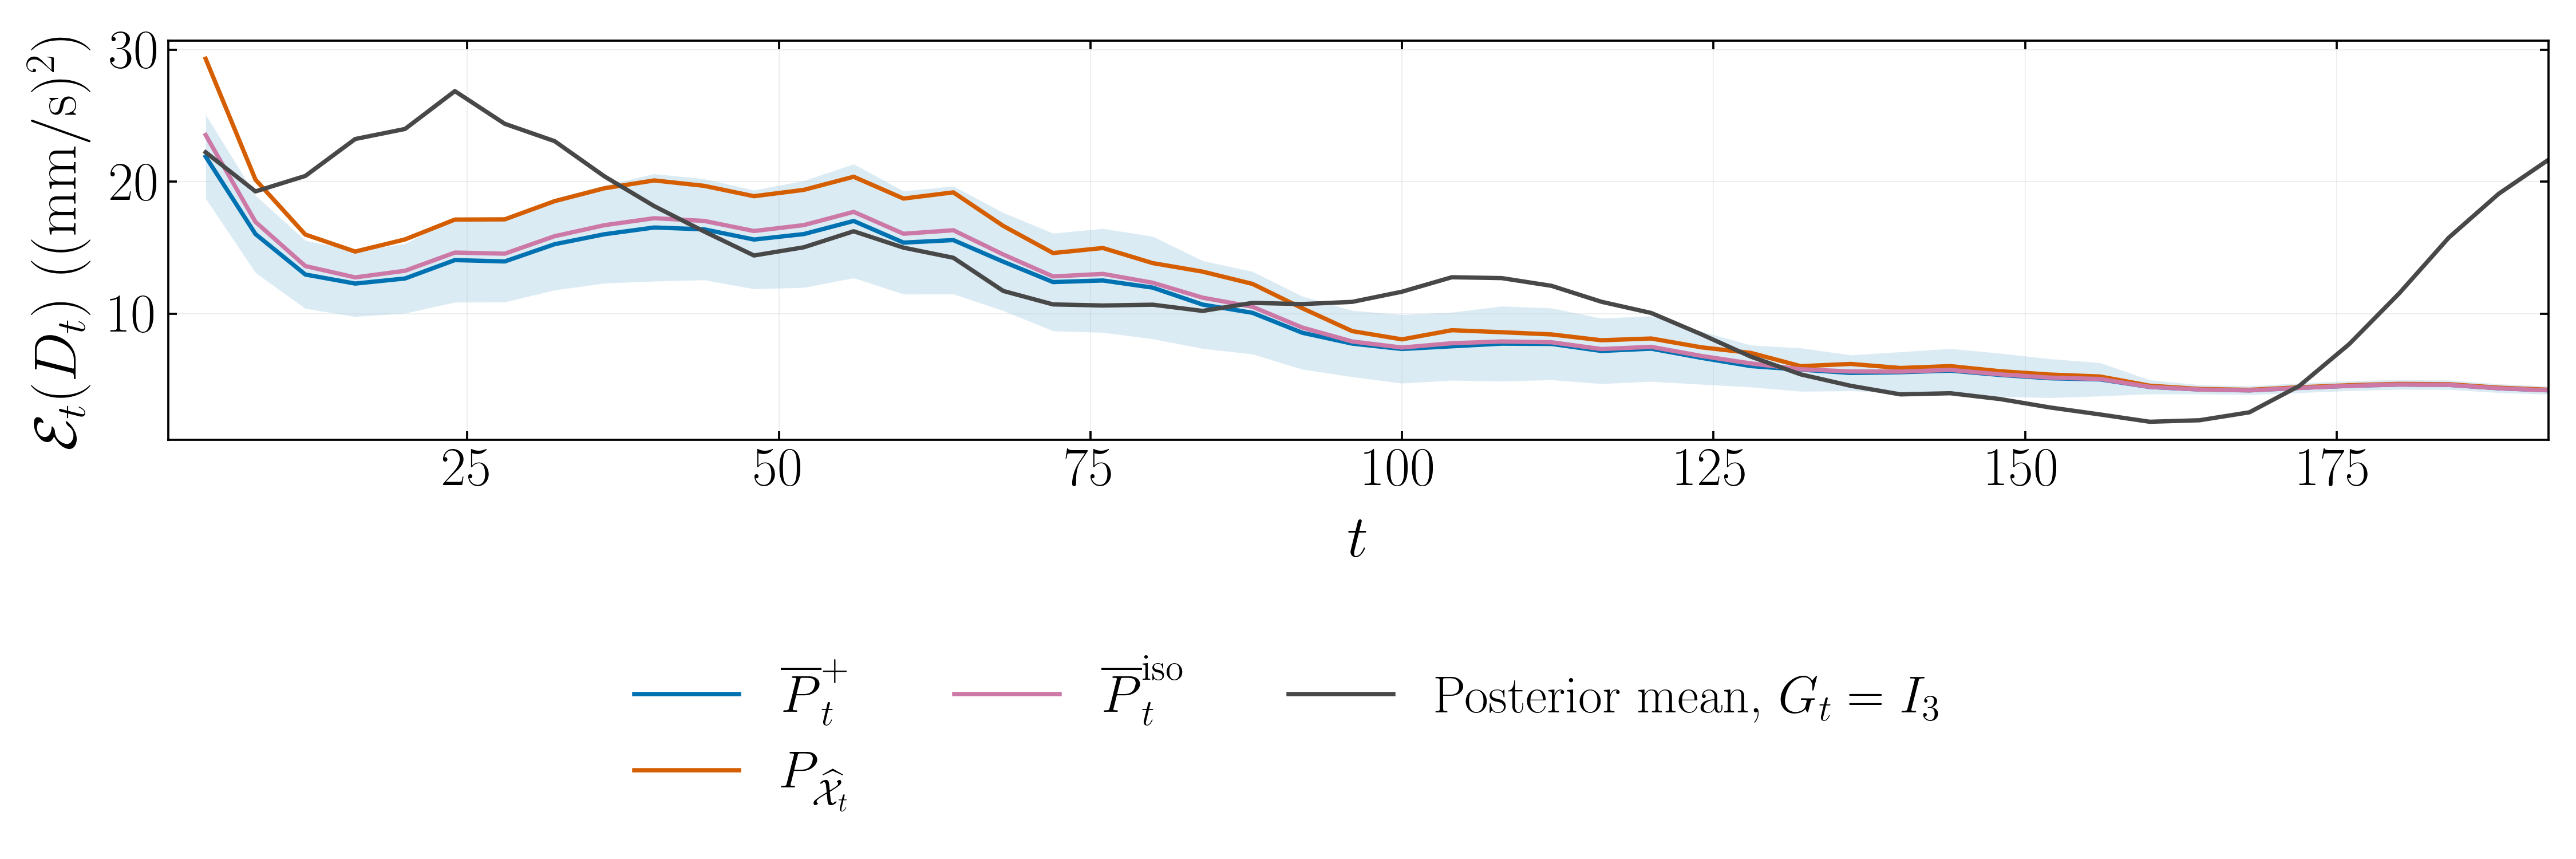

In [6]:
# Edit this figure's canvas, text, colors and save commands directly.
DPI = 300
FIGSIZE = (15, 5)
LABEL_FONT_SIZE = 25.
TICK_FONT_SIZE = 23.
LEGEND_FONT_SIZE = 22.
plt.rcParams.update({
    'text.usetex': True, 'font.family': 'serif', 'font.size': LABEL_FONT_SIZE,
    'axes.labelsize': LABEL_FONT_SIZE, 'axes.titlesize': LABEL_FONT_SIZE,
    'xtick.labelsize': TICK_FONT_SIZE, 'ytick.labelsize': TICK_FONT_SIZE,
    'legend.fontsize': LEGEND_FONT_SIZE, 'axes.labelpad': 8.,
    'figure.dpi': DPI, 'savefig.dpi': DPI,
})
SAVE_PDF = True
PDF_PATH = EDITABLE_OUTPUT / 'prediction_error_sphere.pdf'
DRAFT_SECTION = 'main'
DRAFT_PATH = ROOT / 'results' / DRAFT_SECTION / 'contact' / PDF_PATH.name

LABELS = {
    'mean': r'$\overline P_t^+$', 'mode': r'$P_{\widehat{\mathcal X}_t}$',
    'iso': r'$\overline P_t^{\mathrm{iso}}$',
    'regularized': r'$\widetilde M_t$',
    'great_window': 'GREAT (sliding window)', 'great_ew': 'GREAT (exponential weighting)',
}
COLORS = {'mean':'#0072B2', 'mode':'#D55E00', 'iso':'#CC79A7',
          'regularized':'#8C564B', 'great_window':'#009E73', 'great_ew':'#56B4E9'}

condition = 'sphere'
from lib.contact_transport_diagnostics import load_contact_transport_diagnostics
transport = load_contact_transport_diagnostics(ROOT)
record = {'T': transport['config']['T'], 'curves': transport['sphere_curves']}
fig, ax = plt.subplots(figsize=FIGSIZE, dpi=DPI, layout='constrained')
# All 48 original action times; no interpolation or new simulation settings.
LABELS['mean_identity'] = r'Posterior mean, $G_t=I_3$'
COLORS['mean_identity'] = '#484848'
for curve in record['curves']:
    method = curve['method']
    points = np.asarray(curve['points'], dtype=float)
    ax.plot(points[:, 0], points[:, 1], color=COLORS[method], label=LABELS[method], linestyle='-')
    if method == 'mean':
        ax.fill_between(points[:,0], points[:,2], points[:,3],
                        color=COLORS[method], alpha=.14, linewidth=0)
ax.set(xlabel=r'$t$', ylabel=r'$\mathcal E_t(D_t)$ $((\mathrm{mm}/\mathrm{s})^2)$',
       xlim=(1, int(record['T'])))
BORDER_WIDTH = .9
for spine in ax.spines.values():
    spine.set_visible(True)
    spine.set_linewidth(BORDER_WIDTH)
ax.tick_params(axis='both', which='both', direction='in',
               top=True, right=True, bottom=True, left=True,
               labeltop=False, labelright=False, labelbottom=True, labelleft=True,
               width=BORDER_WIDTH)
ax.xaxis.set_label_position('bottom')
ax.yaxis.set_label_position('left')
ax.grid(color='#BFC4C8', alpha=.30, linewidth=.45)
fig.legend(*ax.get_legend_handles_labels(), loc='outside lower center',
           ncol=3, frameon=False, fontsize=LEGEND_FONT_SIZE)

# Vector text/curves remain in the PDF; surfaces are rasterized at DPI.
fig.get_layout_engine().set(h_pad=.18, w_pad=.16)
if SAVE_PDF:
    PDF_PATH.parent.mkdir(parents=True, exist_ok=True)
    fig.savefig(PDF_PATH, dpi=DPI, bbox_inches=None)
    PNG_PATH = PDF_PATH.with_suffix('.png')
    fig.savefig(PNG_PATH, dpi=DPI, bbox_inches=None)
    DRAFT_PATH.parent.mkdir(parents=True, exist_ok=True)
    DRAFT_PATH.write_bytes(PDF_PATH.read_bytes())
    DRAFT_PNG_PATH = DRAFT_PATH.with_suffix('.png')
    DRAFT_PNG_PATH.write_bytes(PNG_PATH.read_bytes())
plt.show()


## Reference algorithms and paired comparisons

The next plot retains the regularized mode and both GREAT references. Its endpoint is the saved time average over all 48 action times $t=4,8,\ldots,192$ in each sphere simulation,
$\overline{\mathcal E}(D)=48^{-1}\sum_{j=1}^{48}\mathcal E_{4j}(D_{4j})$.
This average uses the same 48 action times shown in the sphere history. The horizontal intervals are pointwise Student 95% intervals for Monte Carlo means. Reference algorithms retain their original selected parameters. The regularized-mode predictor is
$\widetilde M_t=\rho P_{\widehat{\mathcal X}_t}+(1-\rho)\tfrac23I_3$, with the original validation-selected $\rho$. It is generally not a projector.

The mean, mode and regularized mode use the measured velocity, known applied input and measured sensor-frame changes. The isotropic mean uses the same posterior parameter as the full mean. GREAT uses measured velocities and frame changes, without the known applied input. Its comparison therefore changes both the estimator and the available information.

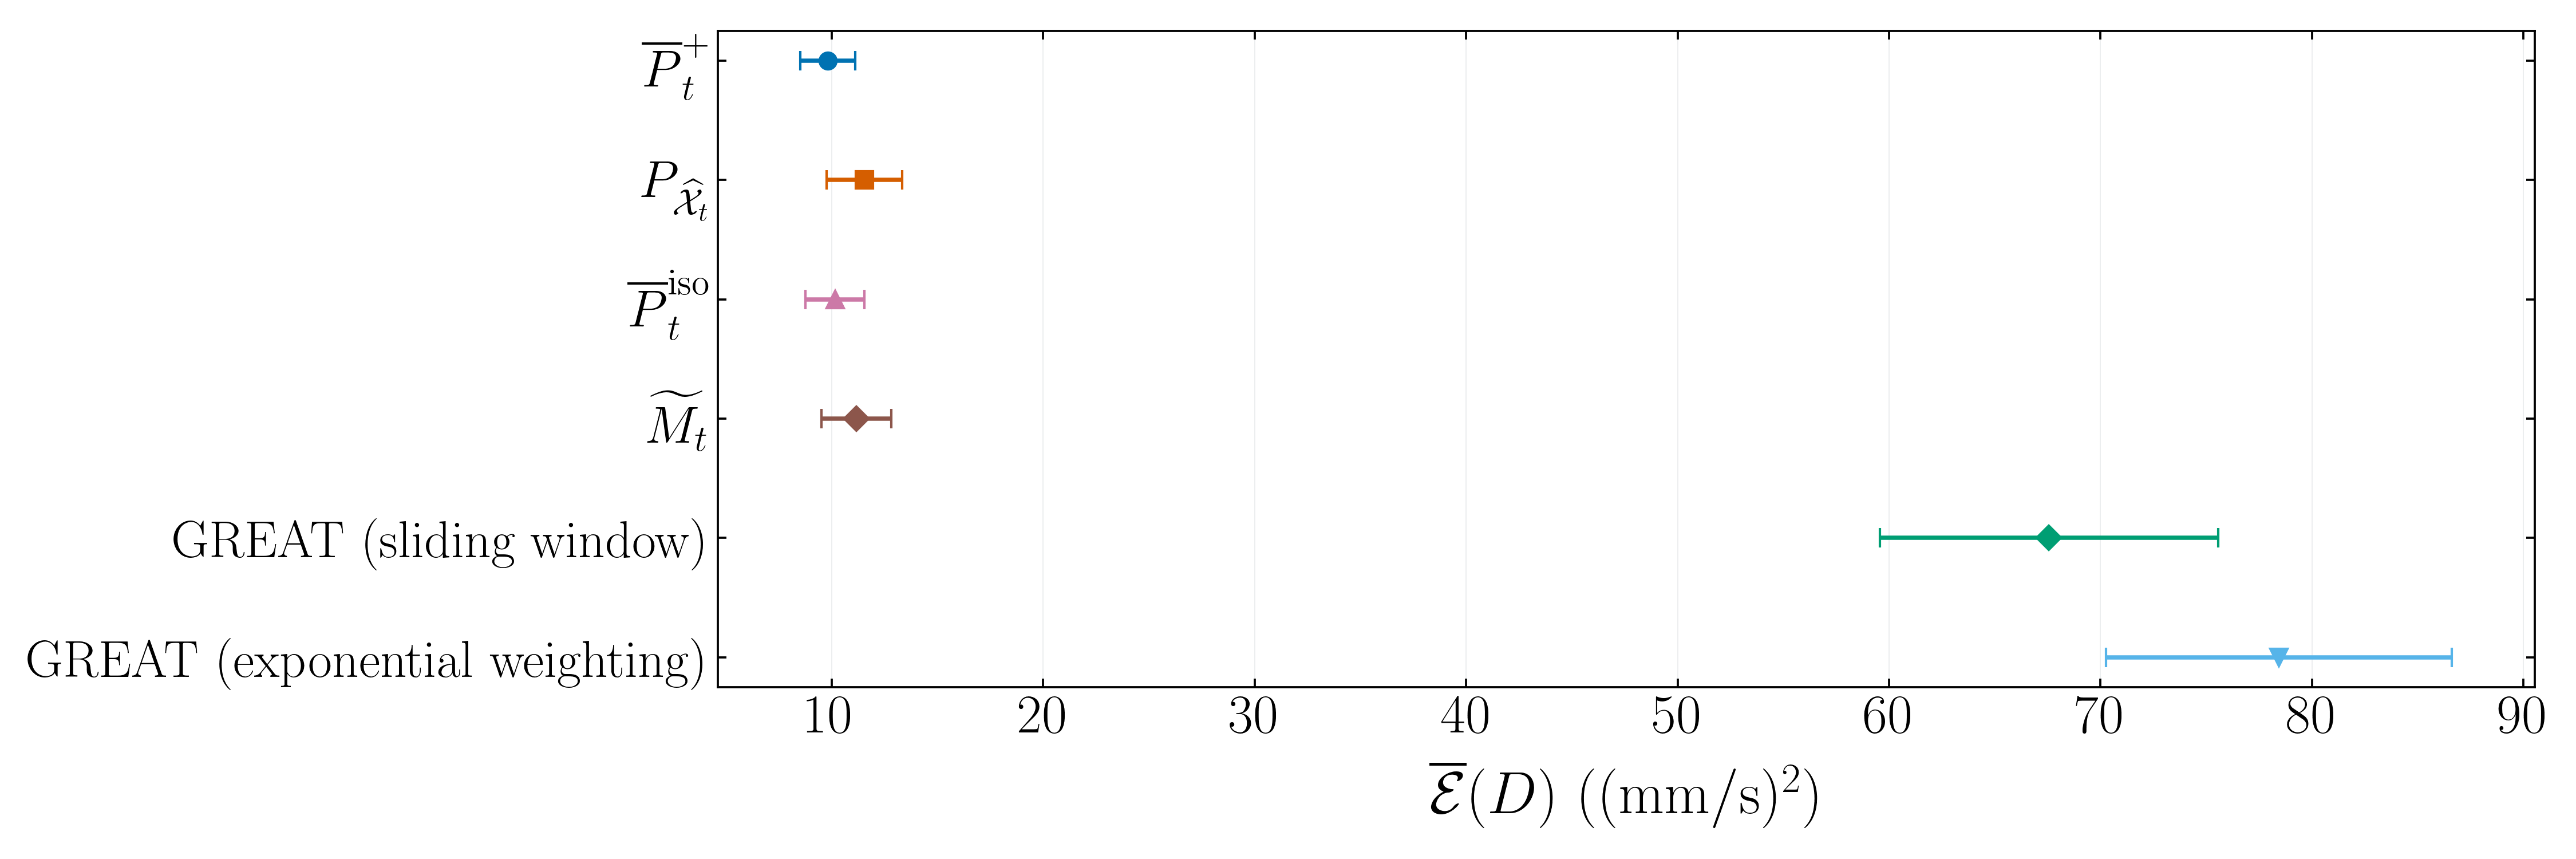

In [4]:
# Edit this figure's canvas, text, colors and save commands directly.
DPI = 300
FIGSIZE = (15, 5)
LABEL_FONT_SIZE = 25.
TICK_FONT_SIZE = 23.
LEGEND_FONT_SIZE = 22.
plt.rcParams.update({
    'text.usetex': True, 'font.family': 'serif', 'font.size': LABEL_FONT_SIZE,
    'axes.labelsize': LABEL_FONT_SIZE, 'axes.titlesize': LABEL_FONT_SIZE,
    'xtick.labelsize': TICK_FONT_SIZE, 'ytick.labelsize': TICK_FONT_SIZE,
    'legend.fontsize': LEGEND_FONT_SIZE, 'axes.labelpad': 8.,
    'figure.dpi': DPI, 'savefig.dpi': DPI,
})
SAVE_PDF = True
PDF_PATH = EDITABLE_OUTPUT / 'prediction_error_references.pdf'
DRAFT_SECTION = 'supplementary'
DRAFT_PATH = ROOT / 'results' / DRAFT_SECTION / 'contact' / PDF_PATH.name

LABELS = {
    'mean': r'$\overline P_t^+$', 'mode': r'$P_{\widehat{\mathcal X}_t}$',
    'iso': r'$\overline P_t^{\mathrm{iso}}$',
    'regularized': r'$\widetilde M_t$',
    'great_window': 'GREAT (sliding window)', 'great_ew': 'GREAT (exponential weighting)',
}
COLORS = {'mean':'#0072B2', 'mode':'#D55E00', 'iso':'#CC79A7',
          'regularized':'#8C564B', 'great_window':'#009E73', 'great_ew':'#56B4E9'}
MARKERS = {'mean':'o', 'mode':'s', 'iso':'^', 'regularized':'D',
           'great_window':'D', 'great_ew':'v'}

# This endpoint averages all 48 scheduled action times inside each simulation.
summary = data['episode_average_summary']
summary = summary[summary.condition.eq('sphere')]
methods = ['mean','mode','iso','regularized','great_window','great_ew']
methods = [method for method in methods if summary.method.eq(method).any()]
fig, ax = plt.subplots(figsize=FIGSIZE, dpi=DPI, layout='constrained')
for position, method in enumerate(methods):
    rows = summary[summary.method.eq(method)]
    if len(rows) != 1:
        raise ValueError('Expected one saved sphere average per method')
    row = rows.iloc[0]
    ax.errorbar(row['mean'], position,
        xerr=[[row['mean']-row['lower']], [row['upper']-row['mean']]],
        fmt=MARKERS[method], color=COLORS[method], capsize=4., markersize=7.)
ax.set(yticks=np.arange(len(methods)), yticklabels=[LABELS[method] for method in methods],
       xlabel=r'$\overline{\mathcal E}(D)$ $((\mathrm{mm}/\mathrm{s})^2)$')
ax.tick_params(axis='y', labelsize=LEGEND_FONT_SIZE)
ax.invert_yaxis()
BORDER_WIDTH = .9
for spine in ax.spines.values():
    spine.set_visible(True)
    spine.set_linewidth(BORDER_WIDTH)
ax.tick_params(axis='both', which='both', direction='in',
               top=True, right=True, bottom=True, left=True,
               labeltop=False, labelright=False, labelbottom=True, labelleft=True,
               width=BORDER_WIDTH)
ax.xaxis.set_label_position('bottom')
ax.yaxis.set_label_position('left')
ax.grid(axis='x', color='#BFC4C8', alpha=.30, linewidth=.45)

# Vector text/curves remain in the PDF; surfaces are rasterized at DPI.
fig.get_layout_engine().set(h_pad=.18, w_pad=.16)
if SAVE_PDF:
    PDF_PATH.parent.mkdir(parents=True, exist_ok=True)
    fig.savefig(PDF_PATH, dpi=DPI, bbox_inches=None)
    PNG_PATH = PDF_PATH.with_suffix('.png')
    fig.savefig(PNG_PATH, dpi=DPI, bbox_inches=None)
    DRAFT_PATH.parent.mkdir(parents=True, exist_ok=True)
    DRAFT_PATH.write_bytes(PDF_PATH.read_bytes())
    DRAFT_PNG_PATH = DRAFT_PATH.with_suffix('.png')
    DRAFT_PNG_PATH.write_bytes(PNG_PATH.read_bytes())
plt.show()


The tables report reference error minus posterior-mean error using the same simulation in each pair, in $(\mathrm{mm}/\mathrm{s})^2$. Positive differences favor the posterior mean. A confidence interval containing zero does not resolve an advantage for that reference and condition. Paired comparisons provide different evidence from overlap of separate mean intervals.

In [5]:
LABELS = {
    'mean': r'$\overline P_t^+$', 'mode': r'$P_{\widehat{\mathcal X}_t}$',
    'iso': r'$\overline P_t^{\mathrm{iso}}$',
    'regularized': r'$\widetilde M_t$',
    'great_window': 'GREAT (sliding window)', 'great_ew': 'GREAT (exponential weighting)',
}
COLORS = {'mean':'#0072B2', 'mode':'#D55E00', 'iso':'#CC79A7',
          'regularized':'#8C564B', 'great_window':'#009E73', 'great_ew':'#56B4E9'}
MARKERS = {'mean':'o', 'mode':'s', 'iso':'^', 'regularized':'D',
           'great_window':'D', 'great_ew':'v'}

# These saved paired summaries use the original simulation identifiers.
comparators = ['mode','iso','regularized','great_window','great_ew']
for label, frame in [
    ('Stationary concentrated inputs at $t=16$', data['paired_checkpoint_summary']),
    ('Moving sphere: all 48 action times', data['paired_episode_average_summary'])]:
    if 'Stationary' in label:
        frame = frame[frame.condition.eq('static_concentrated') & frame.t.eq(16)]
    else:
        frame = frame[frame.condition.eq('sphere')]
    frame = frame[frame.reference.isin(comparators)]
    rows = ['| Reference | Mean difference [95% CI] | Simulations |', '| --- | --- | --- |']
    for row in frame.itertuples():
        rows.append('| '+LABELS[row.reference]+' | '+f'{row.gain:.4g} [{row.lower:.4g}, {row.upper:.4g}]'
                    +' | '+str(row.simulations)+' |')
    display(Markdown('**'+label+'**\n\n'+'\n'.join(rows)))


**Stationary concentrated inputs at $t=16$**

| Reference | Mean difference [95% CI] | Simulations |
| --- | --- | --- |
| $P_{\widehat{\mathcal X}_t}$ | 7.121 [4.33, 9.912] | 256 |
| $\overline P_t^{\mathrm{iso}}$ | 1.373 [0.7284, 2.018] | 256 |
| $\widetilde M_t$ | 6.11 [4.815, 7.404] | 256 |
| GREAT (sliding window) | 47.73 [40.06, 55.4] | 256 |
| GREAT (exponential weighting) | 43.63 [36.09, 51.16] | 256 |

**Moving sphere: all 48 action times**

| Reference | Mean difference [95% CI] | Simulations |
| --- | --- | --- |
| $P_{\widehat{\mathcal X}_t}$ | 1.734 [1.215, 2.253] | 256 |
| $\overline P_t^{\mathrm{iso}}$ | 0.3428 [0.2264, 0.4593] | 256 |
| $\widetilde M_t$ | 1.364 [0.9643, 1.764] | 256 |
| GREAT (sliding window) | 57.76 [50.2, 65.32] | 256 |
| GREAT (exponential weighting) | 68.64 [61.1, 76.17] | 256 |

## The moving posterior at $t=96$

This checkpoint was selected before inspecting its density. It uses the corrected posterior from one saved sphere simulation, in native sensor coordinates. If the plane parameter is $A_t^+$, its unoriented normal has Bingham parameter $B_t=-A_t^+$. The normal $n$ and its antipode $-n$ describe the same plane.

The left sphere shows this full normal posterior. The right sphere is its matched isotropic Bingham comparison, with the same modal normal and mean squared chordal distance from that mode. Both use the same absolute density scale, logarithmic color normalization, sphere mesh and camera. The circle denotes the modal normal $\widehat n_t$ and the star the generating normal $n_t$; one common antipodal sign is used for both markers. The generating normal is used only for evaluation.

This moving checkpoint need not reproduce the strong anisotropy of the controlled concentrated-input example. The actual tangent curvatures and matching error below quantify its shape without changing the experiment.

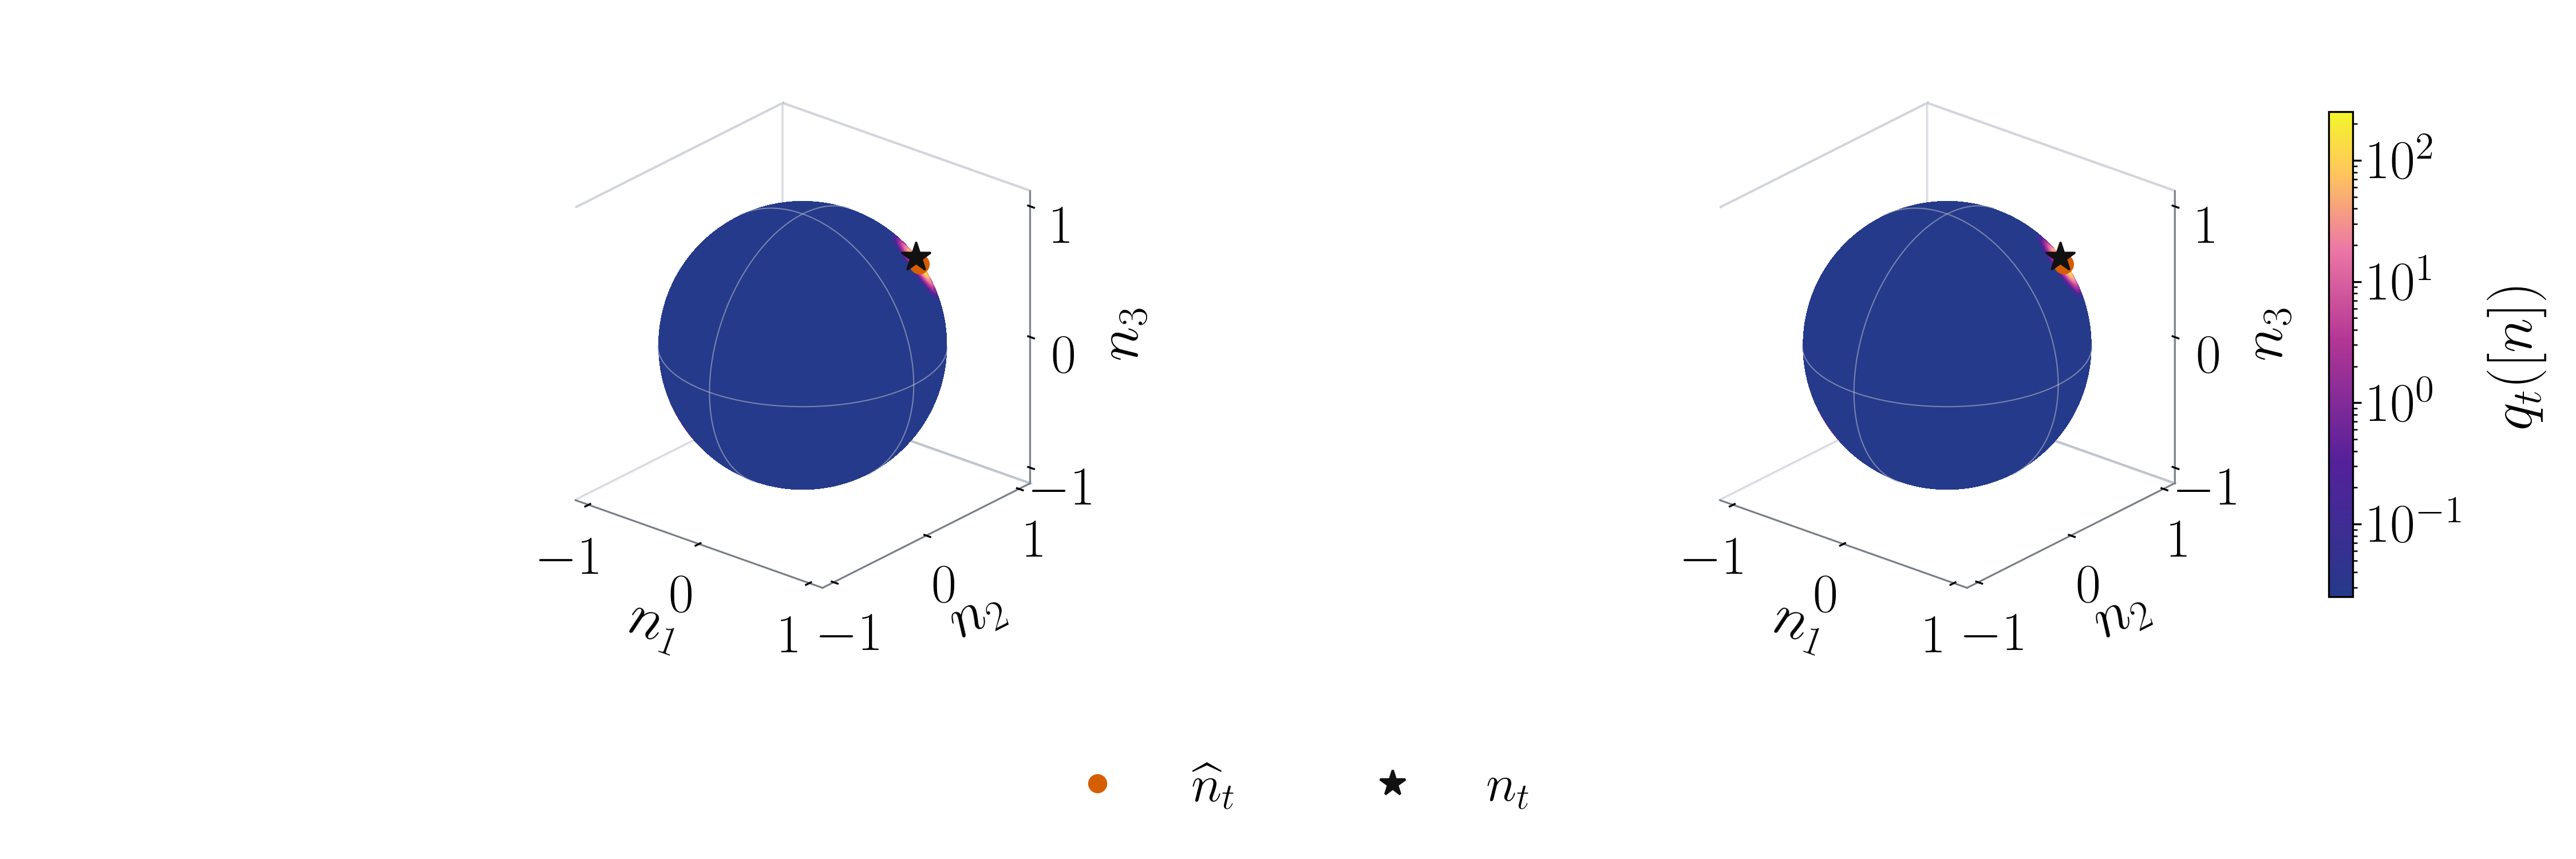

In [6]:
# Edit this figure's canvas, text, colors and save commands directly.
DPI = 300
FIGSIZE = (15, 5)
LABEL_FONT_SIZE = 25.
TICK_FONT_SIZE = 23.
LEGEND_FONT_SIZE = 22.
plt.rcParams.update({
    'text.usetex': True, 'font.family': 'serif', 'font.size': LABEL_FONT_SIZE,
    'axes.labelsize': LABEL_FONT_SIZE, 'axes.titlesize': LABEL_FONT_SIZE,
    'xtick.labelsize': TICK_FONT_SIZE, 'ytick.labelsize': TICK_FONT_SIZE,
    'legend.fontsize': LEGEND_FONT_SIZE, 'axes.labelpad': 8.,
    'figure.dpi': DPI, 'savefig.dpi': DPI,
})
SAVE_PDF = True
PDF_PATH = EDITABLE_OUTPUT / 'moving_sphere_posterior_spheres.pdf'
DRAFT_SECTION = 'supplementary'
DRAFT_PATH = ROOT / 'results' / DRAFT_SECTION / 'contact' / PDF_PATH.name

LABELS = {
    'mean': r'$\overline P_t^+$', 'mode': r'$P_{\widehat{\mathcal X}_t}$',
    'iso': r'$\overline P_t^{\mathrm{iso}}$',
    'regularized': r'$\widetilde M_t$',
    'great_window': 'GREAT (sliding window)', 'great_ew': 'GREAT (exponential weighting)',
}
COLORS = {'mean':'#0072B2', 'mode':'#D55E00', 'iso':'#CC79A7',
          'regularized':'#8C564B', 'great_window':'#009E73', 'great_ew':'#56B4E9'}
MARKERS = {'mean':'o', 'mode':'s', 'iso':'^', 'regularized':'D',
           'great_window':'D', 'great_ew':'v'}

# The same native sensor-coordinate sphere mesh and density scale are used twice.
nodes = np.asarray(snapshot['nodes'])
log_densities = [snapshot['log_density_full'], snapshot['log_density_isotropic']]
mode = np.asarray(snapshot['mode'], dtype=float)
true_normal = np.asarray(snapshot['true_normal'], dtype=float)
ELEVATION, AZIMUTH = 25., -50.
el, az = np.deg2rad([ELEVATION, AZIMUTH])
view_direction = np.array([np.cos(el)*np.cos(az), np.cos(el)*np.sin(az), np.sin(el)])
# Apply one common antipodal sign to both markers; no coordinate rotation is used.
display_sign = 1. if mode @ view_direction >= 0. else -1.
display_mode, display_truth = display_sign*mode, display_sign*true_normal
cmap = colors.LinearSegmentedColormap.from_list('blue_purple_pink_yellow', [
    (0.,'#263a8b'), (.28,'#55209a'), (.53,'#b33695'),
    (.72,'#ed78a4'), (.88,'#ffc85a'), (1.,'#f4f52b')], N=256)
norm = colors.LogNorm(vmin=snapshot['density_limits'][0],
                      vmax=snapshot['density_limits'][1], clip=True)
fig = plt.figure(figsize=FIGSIZE, dpi=DPI, layout='constrained')
axes = [fig.add_subplot(1,2,index+1,projection='3d') for index in range(2)]
for ax, log_density in zip(axes, log_densities):
    ax.computed_zorder = False
    surface = ax.plot_surface(nodes[...,0], nodes[...,1], nodes[...,2],
        facecolors=cmap(norm(np.exp(log_density))), shade=False, linewidth=0,
        antialiased=False, rstride=1, cstride=1, zorder=1)
    surface.set_rasterized(True)
    phi = np.linspace(0., 2*np.pi, 241)
    for plane in [(0,1),(0,2),(1,2)]:
        ring = np.zeros((len(phi),3))
        ring[:,plane[0]], ring[:,plane[1]] = 1.006*np.cos(phi), 1.006*np.sin(phi)
        visible = np.where((ring @ view_direction >= 0.)[:,None], ring, np.nan)
        ax.plot(*visible.T, color='#B7C0CB', linewidth=.5, alpha=.55, zorder=3)
    ax.scatter(*display_mode, color='#D55E00', marker='o', s=55,
               depthshade=False, zorder=5)
    ax.scatter(*display_truth, color='#111111', marker='*', s=150,
               depthshade=False, zorder=6)
    ax.set_proj_type('ortho')
    ax.view_init(elev=ELEVATION, azim=AZIMUTH)
    ax.set_box_aspect((1.,1.,1.), zoom=.84)
    ax.set(xlim=(-1.12,1.12), ylim=(-1.12,1.12), zlim=(-1.12,1.12),
           xticks=(-1.,0.,1.), yticks=(-1.,0.,1.), zticks=(-1.,0.,1.))
    ax.set_xlabel(r'$n_1$', labelpad=8.)
    ax.set_ylabel(r'$n_2$', labelpad=8.)
    ax.set_zlabel(r'$n_3$', labelpad=8.)
    ax.tick_params(labelsize=TICK_FONT_SIZE, pad=3, length=1)
    ax.grid(False)
    for axis in [ax.xaxis,ax.yaxis,ax.zaxis]:
        axis.pane.set_facecolor((1.,1.,1.,0.))
        axis.pane.set_edgecolor((.65,.68,.72,.35))
        axis.line.set_color('#70777D')
        axis.line.set_linewidth(.6)
fig.colorbar(plt.cm.ScalarMappable(norm=norm,cmap=cmap), ax=axes,
             label=r'$q_t([n])$', shrink=.75, pad=.03)
fig.legend(handles=[
    Line2D([],[],marker='o',linestyle='none',color='#D55E00',markersize=7,label=r'$\widehat n_t$'),
    Line2D([],[],marker='*',linestyle='none',color='#111111',markersize=11,label=r'$n_t$')],
    loc='outside lower center', ncol=2, frameon=False, fontsize=LEGEND_FONT_SIZE)

# Vector text/curves remain in the PDF; surfaces are rasterized at DPI.
fig.get_layout_engine().set(h_pad=.18, w_pad=.16)
if SAVE_PDF:
    PDF_PATH.parent.mkdir(parents=True, exist_ok=True)
    fig.savefig(PDF_PATH, dpi=DPI, bbox_inches=None)
    PNG_PATH = PDF_PATH.with_suffix('.png')
    fig.savefig(PNG_PATH, dpi=DPI, bbox_inches=None)
    DRAFT_PATH.parent.mkdir(parents=True, exist_ok=True)
    DRAFT_PATH.write_bytes(PDF_PATH.read_bytes())
    DRAFT_PNG_PATH = DRAFT_PATH.with_suffix('.png')
    DRAFT_PNG_PATH.write_bytes(PNG_PATH.read_bytes())
plt.show()


In [7]:
full = np.asarray(snapshot['curvature_eigenvalues'])
isotropic = np.asarray(snapshot['isotropic_curvature_eigenvalues'])
mode = np.asarray(snapshot['mode'])
M = np.asarray(snapshot['normal_mean'])
M_iso = np.asarray(snapshot['normal_mean_isotropic'])
full_radius = 1.-float(mode @ M @ mode)
iso_radius = 1.-float(mode @ M_iso @ mode)
rows = [
    ['First tangent curvature', full[0], isotropic[0]],
    ['Second tangent curvature', full[1], isotropic[1]],
    ['Mean squared chordal distance from the mode', full_radius, iso_radius],
]
display(pd.DataFrame(rows, columns=['Quantity','Full posterior','Isotropic comparison']))
print('Absolute mean squared chordal-distance matching error:', abs(full_radius-iso_radius))
print('Full-posterior tangent curvature ratio:', float(full.max()/full.min()))
print('Antipodal angle between the mode and generating normal (degrees):',
      snapshot['checks']['antipodal_mode_true_angle_deg'])
display(Markdown('The tangent curvatures are '+f'{full[0]:.2f} and {full[1]:.2f}'+
    ', with ratio '+f'{full.max()/full.min():.3f}'+
    '. This moving posterior has modest anisotropy. The common density scale and these numerical values describe the actual saved checkpoint.'))


,Quantity,Full posterior,Isotropic comparison
0,First tangent curvature,230.935293,252.153300
1,Second tangent curvature,277.685999,252.153300
2,Mean squared chordal distance from the mode,0.007964,0.007964


Absolute mean squared chordal-distance matching error: 1.1102230246251565e-16
Full-posterior tangent curvature ratio: 1.202440716185526
Antipodal angle between the mode and generating normal (degrees): 4.261287810209432


The tangent curvatures are 230.94 and 277.69, with ratio 1.202. This moving posterior has modest anisotropy. The common density scale and these numerical values describe the actual saved checkpoint.

## What the prediction comparisons show

Across all 48 sphere action times, the mean errors are 9.8066, 11.5409 and 10.1494 $(\mathrm{mm}/\mathrm{s})^2$ for the posterior mean, mode and isotropic mean. The paired mode-minus-mean difference is 1.7343 [1.2154, 2.2532], and the isotropic-minus-mean difference is 0.3428 [0.2264, 0.4593] in the same units (pointwise 95% intervals). The positive paired difference against the matched isotropic mean supports the value of directional posterior moments for this saved condition. It does not imply the same ordering at every time.

Across the same 48 action times, the paired identity-transport-minus-measured-transport posterior-mean error is 2.6548 [2.0956, 3.2140] $(\mathrm{mm}/\mathrm{s})^2$ (pointwise 95% interval across 256 simulations). This uses the original whole-run episode-average records, which agree with the recovered 48-action histories.

## Interpretation and links to the controlled example

A lower clean-velocity error supports a prediction advantage for the particular condition and selected settings. These comparisons do not establish a general coverage guarantee under physical drift. The moving sphere and stationary concentrated-input experiments answer different questions; the same ranking need not hold at every time or against every reference.

The two posterior laws can also have different conditional response variances,
$\operatorname{tr}\operatorname{Cov}_{q_t}(P_{\mathcal X_t}v)=v^\top[\overline P_t-(\overline P_t)^2]v$. Each such value belongs to its own law and its own posterior mean. It is not the empirical prediction error against a common generating trajectory. This notebook keeps those interpretations separate.

The existing [controlled normal-rotation calculation](../results/main/contact/information_rotation.pdf) and [concentrated-input posterior spheres](../results/main/contact/posterior_anisotropy_spheres.pdf) remain unchanged. There, $p_Z$ denotes the velocity observation law at the plane specified by graph coordinate $Z$; its divergence compares observation laws, rather than posterior credible regions. That controlled example establishes how directional information can differ. The moving snapshot here reports the shape actually obtained during the saved physical trajectory.

The figure code is fully visible above. `SAVE_PDF` controls both local PDF/PNG exports and copies into the manuscript's main or supplementary folder.

## Additional diagnostics for measured transport

These plots use a separately verified replay of the same 256 sphere simulations, with all original settings and action times unchanged. No event is introduced at $t=128$.

For each simulation, define $\Delta\mathcal E=\mathcal E_{192}(D_{192})-\mathcal E_{128}(D_{128})$. The empirical cumulative distribution below retains both positive and negative changes. It compares the posterior mean with measured transport to the same estimator with $G_t=I_3$. A time increase for the identity control alone does not identify a universal cause of error under physical drift.

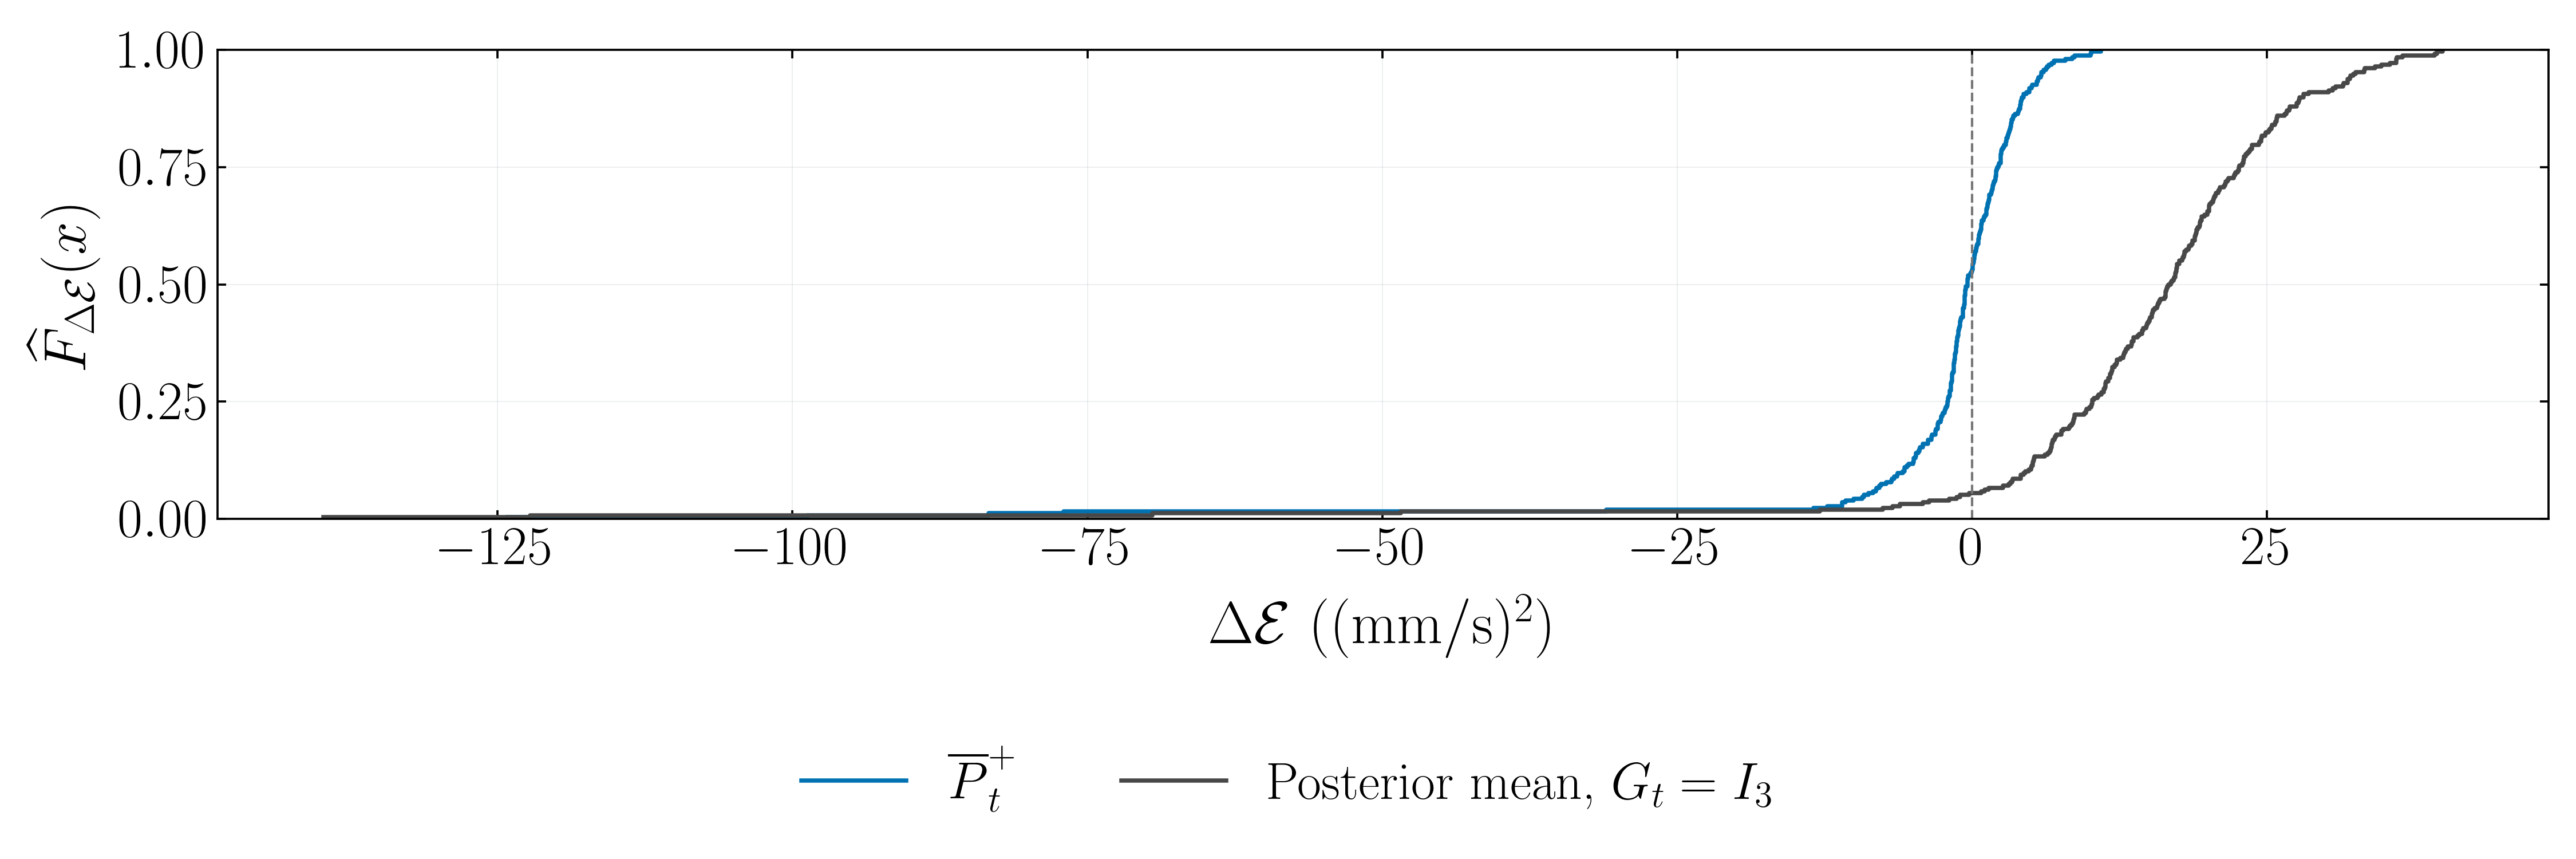

In [7]:
# Edit this figure's canvas, text, colors and save commands directly.
DPI = 300
FIGSIZE = (15, 5)
LABEL_FONT_SIZE = 25.
TICK_FONT_SIZE = 23.
LEGEND_FONT_SIZE = 22.
plt.rcParams.update({
    'text.usetex': True, 'font.family': 'serif', 'font.size': LABEL_FONT_SIZE,
    'axes.labelsize': LABEL_FONT_SIZE, 'axes.titlesize': LABEL_FONT_SIZE,
    'xtick.labelsize': TICK_FONT_SIZE, 'ytick.labelsize': TICK_FONT_SIZE,
    'legend.fontsize': LEGEND_FONT_SIZE, 'axes.labelpad': 8.,
    'figure.dpi': DPI, 'savefig.dpi': DPI,
})
SAVE_PDF = True
TRANSPORT_OUTPUT = ROOT / 'results/contact_transport_diagnostics/figures'
PDF_PATH = TRANSPORT_OUTPUT / 'transport_paired_rise.pdf'
DRAFT_SECTION = 'supplementary'
DRAFT_PATH = ROOT / 'results' / DRAFT_SECTION / 'contact' / PDF_PATH.name

LABELS = {
    'mean': r'$\overline P_t^+$', 'mode': r'$P_{\widehat{\mathcal X}_t}$',
    'iso': r'$\overline P_t^{\mathrm{iso}}$',
    'regularized': r'$\widetilde M_t$',
    'great_window': 'GREAT (sliding window)', 'great_ew': 'GREAT (exponential weighting)',
}
COLORS = {'mean':'#0072B2', 'mode':'#D55E00', 'iso':'#CC79A7',
          'regularized':'#8C564B', 'great_window':'#009E73', 'great_ew':'#56B4E9'}

from lib.contact_transport_diagnostics import load_contact_transport_diagnostics
transport = load_contact_transport_diagnostics(ROOT)

# Each difference uses the same simulation at the two recorded action times.
frame = transport['late_rise_trials']
LABELS['mean_identity'] = r'Posterior mean, $G_t=I_3$'
COLORS['mean_identity'] = '#484848'
fig, ax = plt.subplots(figsize=FIGSIZE, dpi=DPI, layout='constrained')
for method in ['mean', 'mean_identity']:
    values = np.sort(frame.loc[frame.method.eq(method), 'difference_mm2_s2'].to_numpy())
    probability = np.arange(1, len(values)+1, dtype=float)/len(values)
    ax.step(values, probability, where='post', color=COLORS[method],
            linestyle='-', label=LABELS[method])
ax.axvline(0., color='#777777', linestyle='--', linewidth=1.)
ax.set(xlabel=r'$\Delta\mathcal E$ $((\mathrm{mm}/\mathrm{s})^2)$',
       ylabel=r'$\widehat F_{\Delta\mathcal E}(x)$', ylim=(0., 1.))

BORDER_WIDTH = .9
for spine in ax.spines.values():
    spine.set_visible(True)
    spine.set_linewidth(BORDER_WIDTH)
ax.tick_params(axis='both', which='both', direction='in',
               top=True, right=True, bottom=True, left=True,
               labeltop=False, labelright=False, labelbottom=True, labelleft=True,
               width=BORDER_WIDTH)
ax.xaxis.set_label_position('bottom')
ax.yaxis.set_label_position('left')
ax.grid(color='#BFC4C8', alpha=.30, linewidth=.45)
fig.legend(*ax.get_legend_handles_labels(), loc='outside lower center',
           ncol=3, frameon=False, fontsize=LEGEND_FONT_SIZE)

# Vector text/curves remain in the PDF; surfaces are rasterized at DPI.
fig.get_layout_engine().set(h_pad=.18, w_pad=.16)
if SAVE_PDF:
    PDF_PATH.parent.mkdir(parents=True, exist_ok=True)
    fig.savefig(PDF_PATH, dpi=DPI, bbox_inches=None)
    PNG_PATH = PDF_PATH.with_suffix('.png')
    fig.savefig(PNG_PATH, dpi=DPI, bbox_inches=None)
    DRAFT_PATH.parent.mkdir(parents=True, exist_ok=True)
    DRAFT_PATH.write_bytes(PDF_PATH.read_bytes())
    DRAFT_PNG_PATH = DRAFT_PATH.with_suffix('.png')
    DRAFT_PNG_PATH.write_bytes(PNG_PATH.read_bytes())
plt.show()


### Physical motion and coordinate changes

Here $P_t=R_t^\top P_t^{\mathrm{world}}R_t$ is the generating sensor-frame projector, used only for evaluation. The first curve includes the change of sensor coordinates. The second transports the preceding projector with the measured $G_t$ before comparing it to the current one, isolating the physical projector increment. Curves are means over the same 256 simulations, whose initial normals and physical paths vary; their confidence intervals remain in the exported table and are omitted here. The transported increment agrees with the world-coordinate increment in each simulation, which is retained as a numerical check.

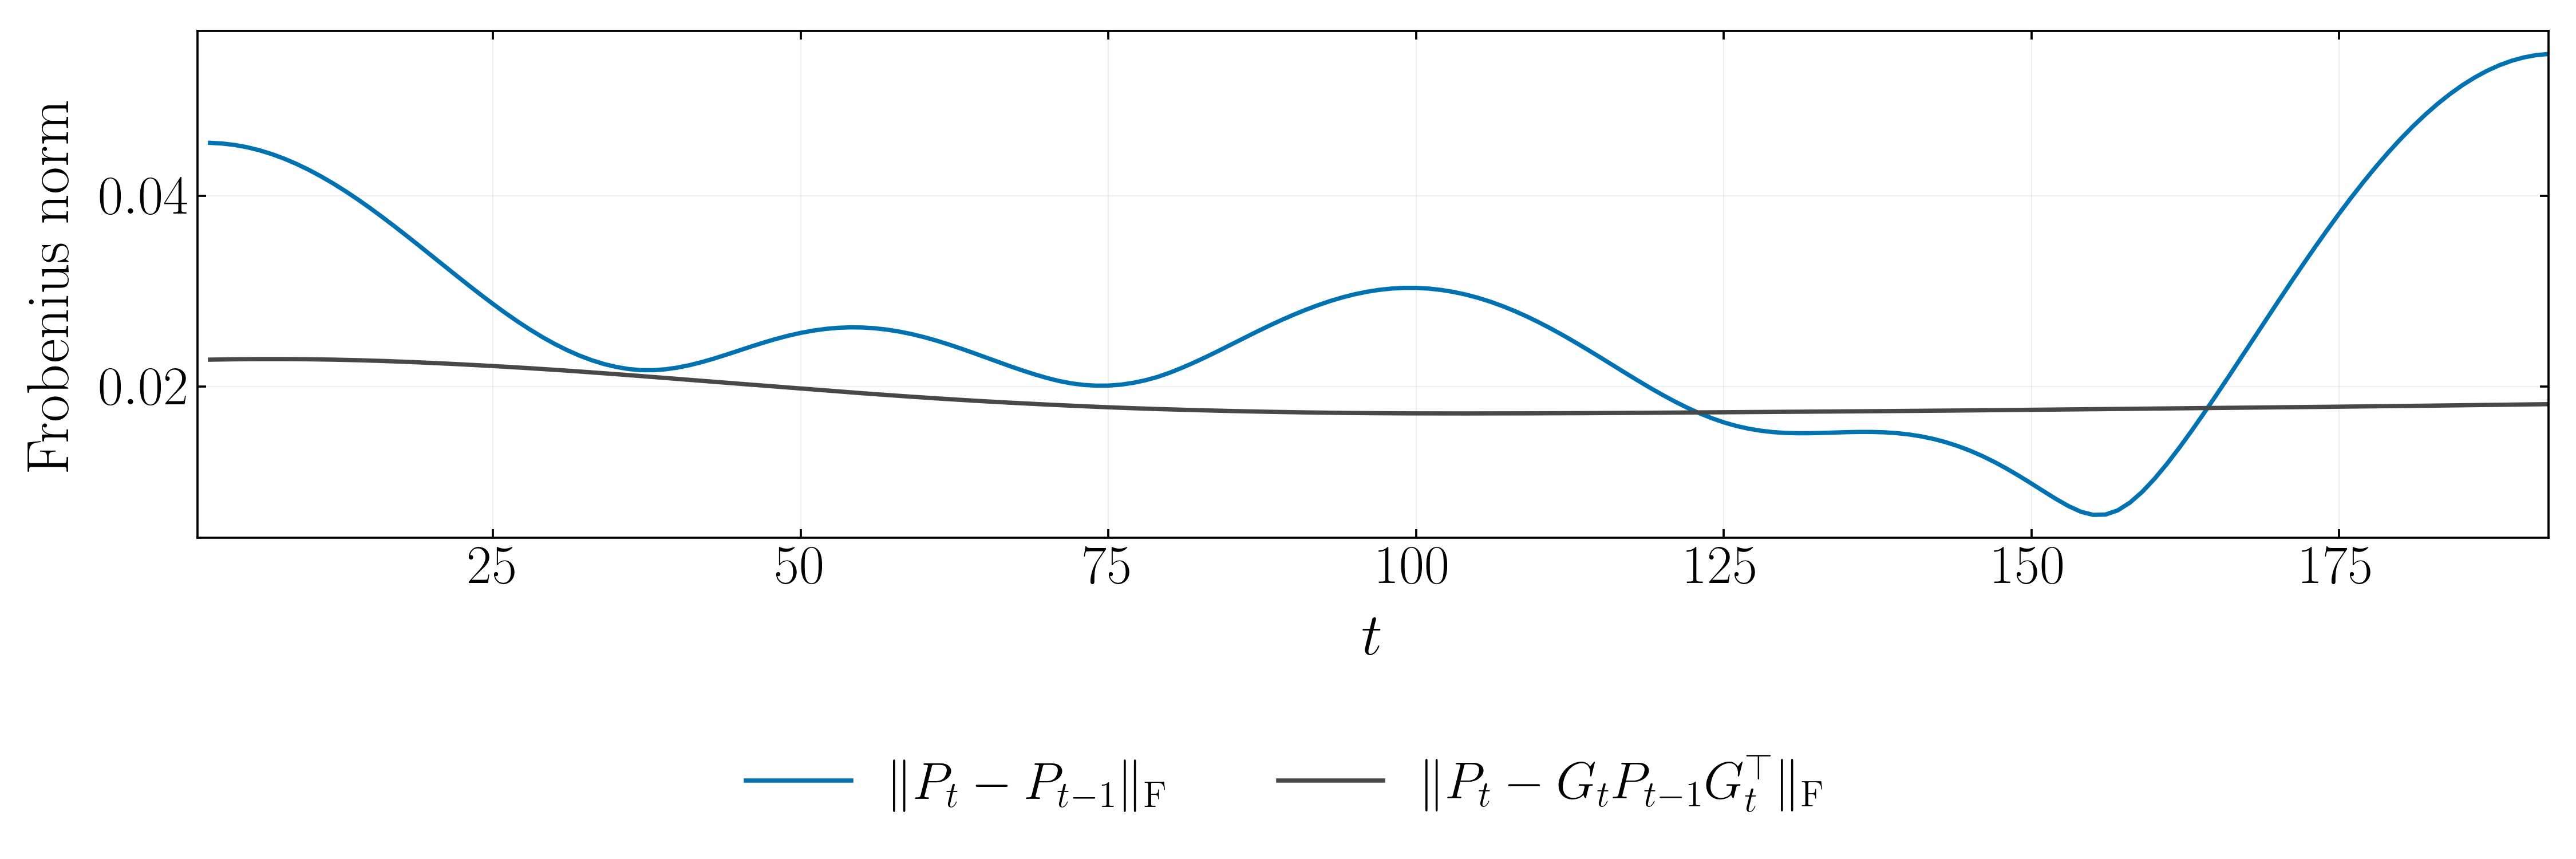

In [8]:
# Edit this figure's canvas, text, colors and save commands directly.
DPI = 300
FIGSIZE = (15, 5)
LABEL_FONT_SIZE = 25.
TICK_FONT_SIZE = 23.
LEGEND_FONT_SIZE = 22.
plt.rcParams.update({
    'text.usetex': True, 'font.family': 'serif', 'font.size': LABEL_FONT_SIZE,
    'axes.labelsize': LABEL_FONT_SIZE, 'axes.titlesize': LABEL_FONT_SIZE,
    'xtick.labelsize': TICK_FONT_SIZE, 'ytick.labelsize': TICK_FONT_SIZE,
    'legend.fontsize': LEGEND_FONT_SIZE, 'axes.labelpad': 8.,
    'figure.dpi': DPI, 'savefig.dpi': DPI,
})
SAVE_PDF = True
TRANSPORT_OUTPUT = ROOT / 'results/contact_transport_diagnostics/figures'
PDF_PATH = TRANSPORT_OUTPUT / 'transport_projector_change.pdf'
DRAFT_SECTION = 'supplementary'
DRAFT_PATH = ROOT / 'results' / DRAFT_SECTION / 'contact' / PDF_PATH.name

LABELS = {
    'mean': r'$\overline P_t^+$', 'mode': r'$P_{\widehat{\mathcal X}_t}$',
    'iso': r'$\overline P_t^{\mathrm{iso}}$',
    'regularized': r'$\widetilde M_t$',
    'great_window': 'GREAT (sliding window)', 'great_ew': 'GREAT (exponential weighting)',
}
COLORS = {'mean':'#0072B2', 'mode':'#D55E00', 'iso':'#CC79A7',
          'regularized':'#8C564B', 'great_window':'#009E73', 'great_ew':'#56B4E9'}

from lib.contact_transport_diagnostics import load_contact_transport_diagnostics
transport = load_contact_transport_diagnostics(ROOT)

# These are Monte Carlo means of the generating geometric increments.
frame = transport['projector_changes']
metric_styles = {
    'sensor_increment_fro': (r'$\|P_t-P_{t-1}\|_{\mathrm F}$', '#0072B2'),
    'transported_increment_fro':
        (r'$\|P_t-G_tP_{t-1}G_t^\top\|_{\mathrm F}$', '#484848'),
}
fig, ax = plt.subplots(figsize=FIGSIZE, dpi=DPI, layout='constrained')
for metric, (label, color_) in metric_styles.items():
    rows = frame[frame.metric.eq(metric)].sort_values('t')
    ax.plot(rows.t, rows['mean'], color=color_, linestyle='-', label=label)
ax.set(xlabel=r'$t$', ylabel='Frobenius norm', xlim=(1, transport['config']['T']))

BORDER_WIDTH = .9
for spine in ax.spines.values():
    spine.set_visible(True)
    spine.set_linewidth(BORDER_WIDTH)
ax.tick_params(axis='both', which='both', direction='in',
               top=True, right=True, bottom=True, left=True,
               labeltop=False, labelright=False, labelbottom=True, labelleft=True,
               width=BORDER_WIDTH)
ax.xaxis.set_label_position('bottom')
ax.yaxis.set_label_position('left')
ax.grid(color='#BFC4C8', alpha=.30, linewidth=.45)
fig.legend(*ax.get_legend_handles_labels(), loc='outside lower center',
           ncol=3, frameon=False, fontsize=LEGEND_FONT_SIZE)

# Vector text/curves remain in the PDF; surfaces are rasterized at DPI.
fig.get_layout_engine().set(h_pad=.18, w_pad=.16)
if SAVE_PDF:
    PDF_PATH.parent.mkdir(parents=True, exist_ok=True)
    fig.savefig(PDF_PATH, dpi=DPI, bbox_inches=None)
    PNG_PATH = PDF_PATH.with_suffix('.png')
    fig.savefig(PNG_PATH, dpi=DPI, bbox_inches=None)
    DRAFT_PATH.parent.mkdir(parents=True, exist_ok=True)
    DRAFT_PATH.write_bytes(PDF_PATH.read_bytes())
    DRAFT_PNG_PATH = DRAFT_PATH.with_suffix('.png')
    DRAFT_PNG_PATH.write_bytes(PNG_PATH.read_bytes())
plt.show()


### Information supplied by the known inputs

Let $S_t=\beta G_tS_{t-1}G_t^\top+v_tv_t^\top$ and $s_t=\beta s_{t-1}+1$, where $v_t$ is the known applied input. The dimensionless matrix $H_t=S_t/(\sigma^2s_t)$ uses the original sphere setting $\beta=0.9$; it introduces no additional moving window. Its eigenvalues are ordered increasingly. They describe directional input excitation, not prediction error or posterior coverage. The applied inputs and hence these eigenvalues are deterministic for the shared trajectory; their Monte Carlo intervals collapse.

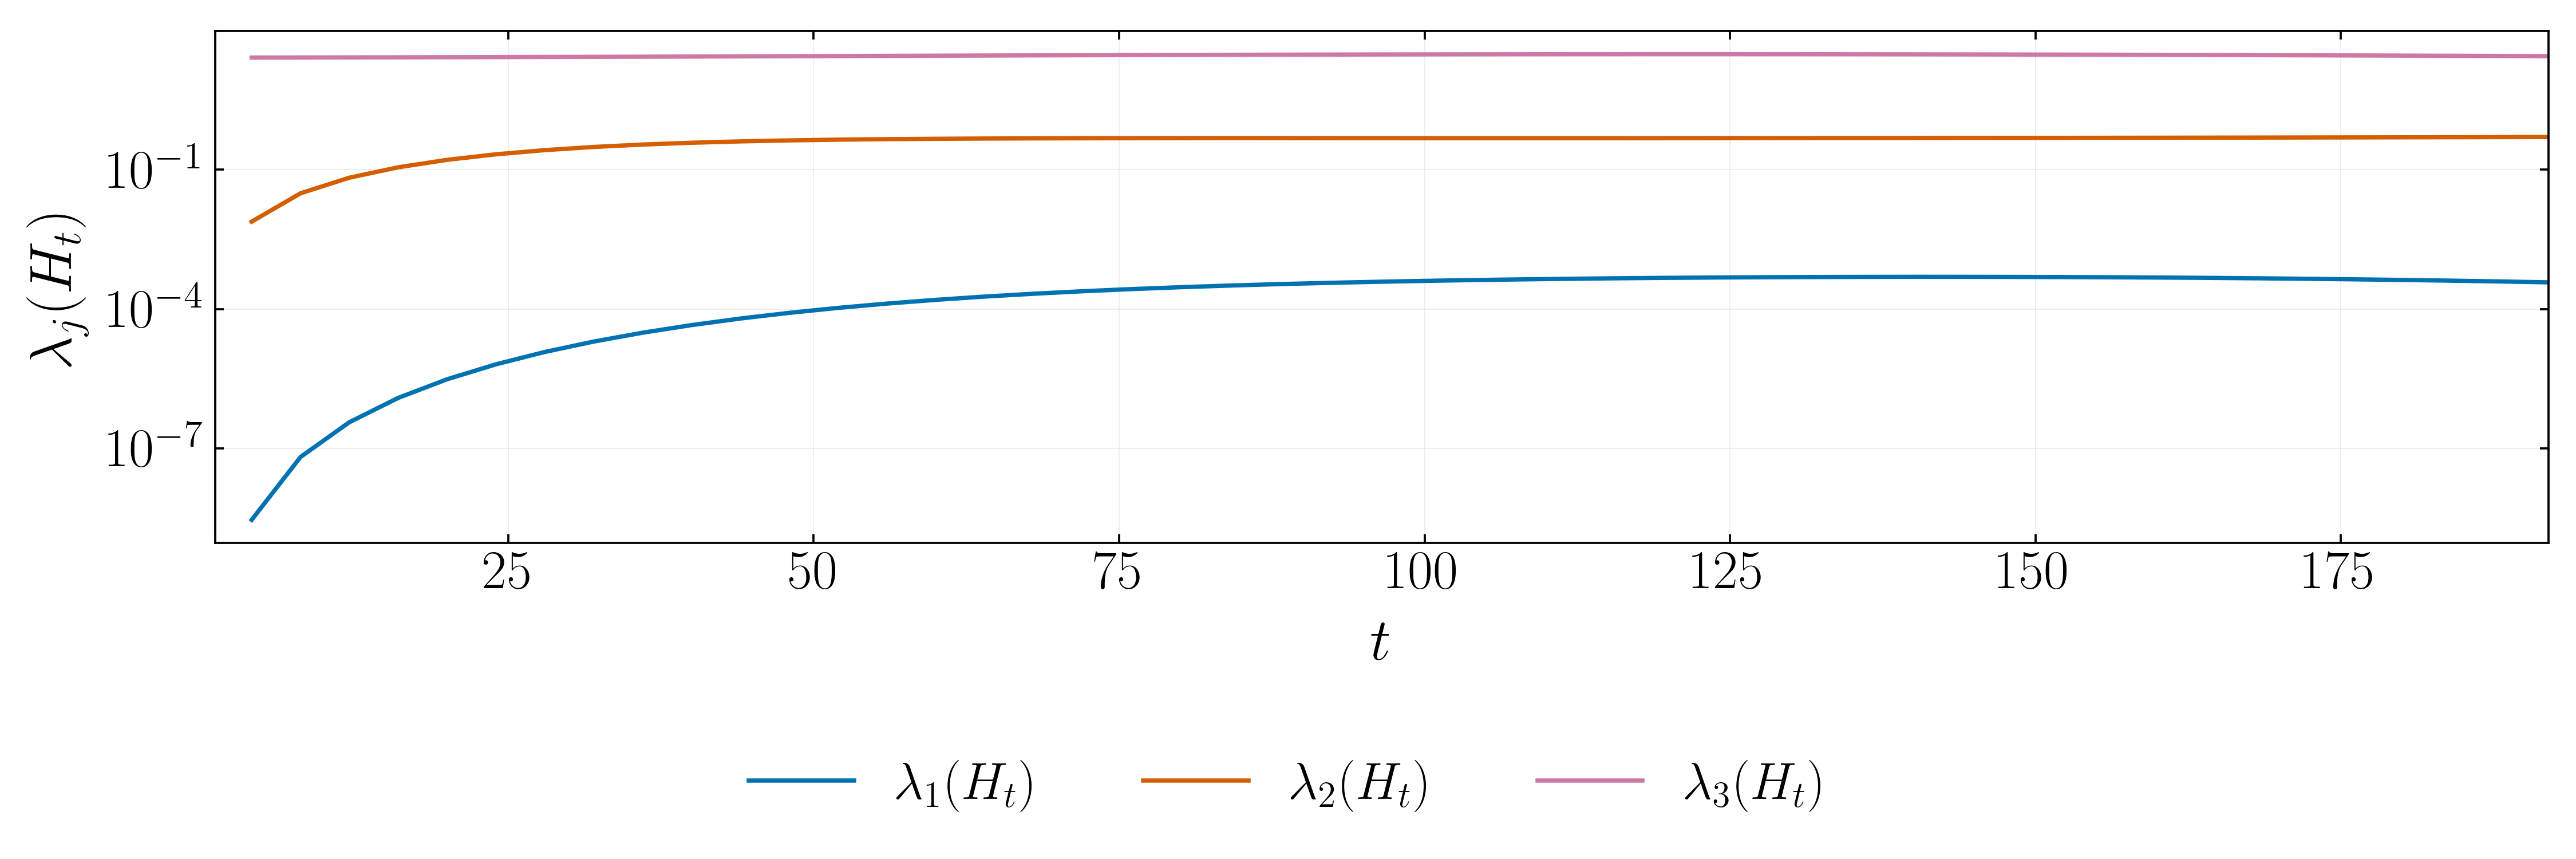

In [9]:
# Edit this figure's canvas, text, colors and save commands directly.
DPI = 300
FIGSIZE = (15, 5)
LABEL_FONT_SIZE = 25.
TICK_FONT_SIZE = 23.
LEGEND_FONT_SIZE = 22.
plt.rcParams.update({
    'text.usetex': True, 'font.family': 'serif', 'font.size': LABEL_FONT_SIZE,
    'axes.labelsize': LABEL_FONT_SIZE, 'axes.titlesize': LABEL_FONT_SIZE,
    'xtick.labelsize': TICK_FONT_SIZE, 'ytick.labelsize': TICK_FONT_SIZE,
    'legend.fontsize': LEGEND_FONT_SIZE, 'axes.labelpad': 8.,
    'figure.dpi': DPI, 'savefig.dpi': DPI,
})
SAVE_PDF = True
TRANSPORT_OUTPUT = ROOT / 'results/contact_transport_diagnostics/figures'
PDF_PATH = TRANSPORT_OUTPUT / 'transport_excitation.pdf'
DRAFT_SECTION = 'supplementary'
DRAFT_PATH = ROOT / 'results' / DRAFT_SECTION / 'contact' / PDF_PATH.name

LABELS = {
    'mean': r'$\overline P_t^+$', 'mode': r'$P_{\widehat{\mathcal X}_t}$',
    'iso': r'$\overline P_t^{\mathrm{iso}}$',
    'regularized': r'$\widetilde M_t$',
    'great_window': 'GREAT (sliding window)', 'great_ew': 'GREAT (exponential weighting)',
}
COLORS = {'mean':'#0072B2', 'mode':'#D55E00', 'iso':'#CC79A7',
          'regularized':'#8C564B', 'great_window':'#009E73', 'great_ew':'#56B4E9'}

from lib.contact_transport_diagnostics import load_contact_transport_diagnostics
transport = load_contact_transport_diagnostics(ROOT)

# H_t is the normalized, exponentially weighted Gram matrix of known inputs.
frame = transport['excitation']
metric_styles = {
    'input_gram_lambda_1': (r'$\lambda_1(H_t)$', '#0072B2'),
    'input_gram_lambda_2': (r'$\lambda_2(H_t)$', '#D55E00'),
    'input_gram_lambda_3': (r'$\lambda_3(H_t)$', '#CC79A7'),
}
fig, ax = plt.subplots(figsize=FIGSIZE, dpi=DPI, layout='constrained')
for metric, (label, color_) in metric_styles.items():
    rows = frame[frame.metric.eq(metric)].sort_values('t')
    ax.plot(rows.t, rows['mean'], color=color_, linestyle='-', label=label)
    if not rows.deterministic.all():
        ax.fill_between(rows.t, rows.lower, rows.upper, color=color_, alpha=.12, linewidth=0)
ax.set(xlabel=r'$t$', ylabel=r'$\lambda_j(H_t)$', xlim=(1, transport['config']['T']))
ax.set_yscale('log')

BORDER_WIDTH = .9
for spine in ax.spines.values():
    spine.set_visible(True)
    spine.set_linewidth(BORDER_WIDTH)
ax.tick_params(axis='both', which='both', direction='in',
               top=True, right=True, bottom=True, left=True,
               labeltop=False, labelright=False, labelbottom=True, labelleft=True,
               width=BORDER_WIDTH)
ax.xaxis.set_label_position('bottom')
ax.yaxis.set_label_position('left')
ax.grid(color='#BFC4C8', alpha=.30, linewidth=.45)
fig.legend(*ax.get_legend_handles_labels(), loc='outside lower center',
           ncol=3, frameon=False, fontsize=LEGEND_FONT_SIZE)

# Vector text/curves remain in the PDF; surfaces are rasterized at DPI.
fig.get_layout_engine().set(h_pad=.18, w_pad=.16)
if SAVE_PDF:
    PDF_PATH.parent.mkdir(parents=True, exist_ok=True)
    fig.savefig(PDF_PATH, dpi=DPI, bbox_inches=None)
    PNG_PATH = PDF_PATH.with_suffix('.png')
    fig.savefig(PNG_PATH, dpi=DPI, bbox_inches=None)
    DRAFT_PATH.parent.mkdir(parents=True, exist_ok=True)
    DRAFT_PATH.write_bytes(PDF_PATH.read_bytes())
    DRAFT_PNG_PATH = DRAFT_PATH.with_suffix('.png')
    DRAFT_PNG_PATH.write_bytes(PNG_PATH.read_bytes())
plt.show()


### Posterior concentration during motion

For ascending eigenvalues of the plane posterior parameter $A_t^+$, define $c_{\min,t}=2[\lambda_2(A_t^+)-\lambda_1(A_t^+)]$ and $c_{\max,t}=2[\lambda_3(A_t^+)-\lambda_1(A_t^+)]$. These are the two angular tangent curvatures of the normal posterior on the unit sphere. Superscript $G=I$ denotes the identity-transport control. Curves show means over the same 256 simulations, and shading gives pointwise Student 95% intervals. Concentration of a model posterior does not by itself establish accuracy under unmodelled physical motion.

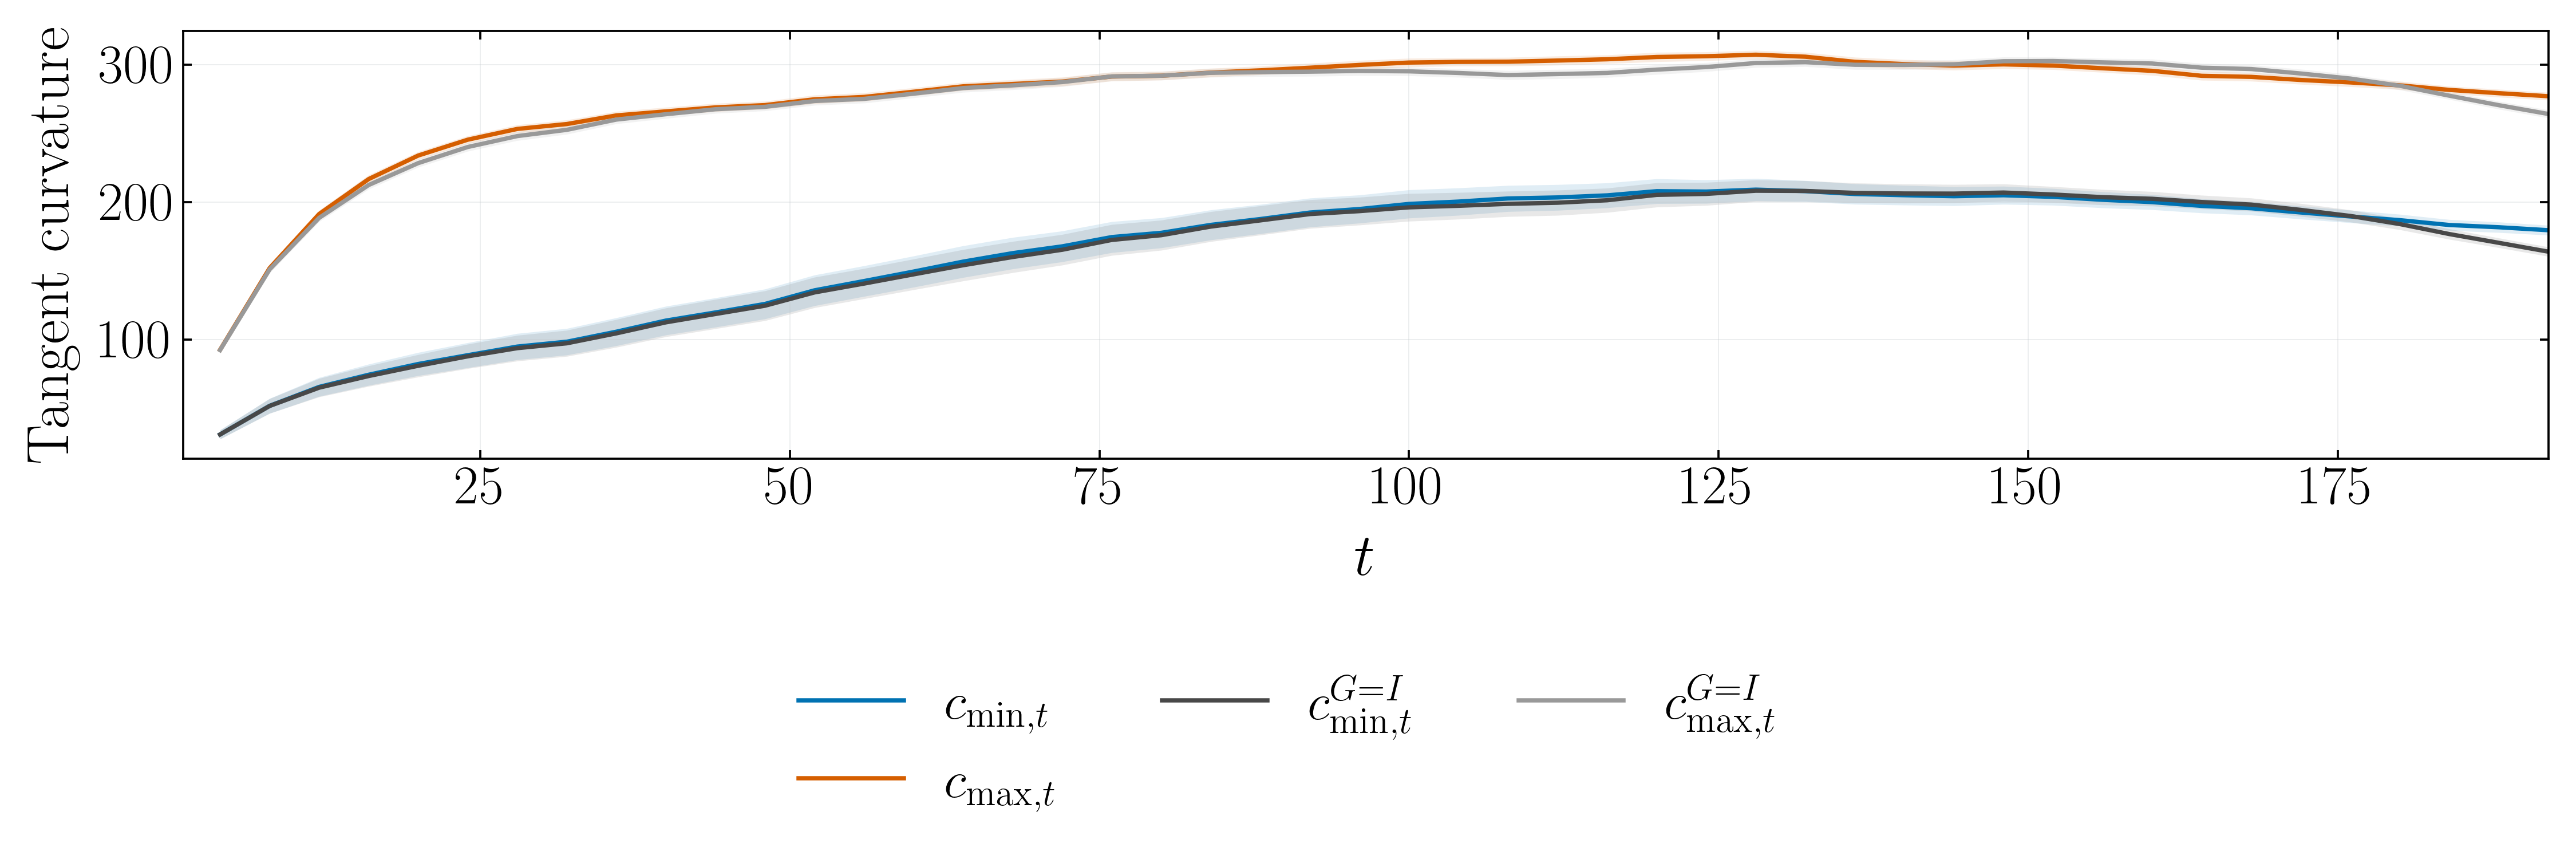

In [10]:
# Edit this figure's canvas, text, colors and save commands directly.
DPI = 300
FIGSIZE = (15, 5)
LABEL_FONT_SIZE = 25.
TICK_FONT_SIZE = 23.
LEGEND_FONT_SIZE = 22.
plt.rcParams.update({
    'text.usetex': True, 'font.family': 'serif', 'font.size': LABEL_FONT_SIZE,
    'axes.labelsize': LABEL_FONT_SIZE, 'axes.titlesize': LABEL_FONT_SIZE,
    'xtick.labelsize': TICK_FONT_SIZE, 'ytick.labelsize': TICK_FONT_SIZE,
    'legend.fontsize': LEGEND_FONT_SIZE, 'axes.labelpad': 8.,
    'figure.dpi': DPI, 'savefig.dpi': DPI,
})
SAVE_PDF = True
TRANSPORT_OUTPUT = ROOT / 'results/contact_transport_diagnostics/figures'
PDF_PATH = TRANSPORT_OUTPUT / 'transport_curvature.pdf'
DRAFT_SECTION = 'supplementary'
DRAFT_PATH = ROOT / 'results' / DRAFT_SECTION / 'contact' / PDF_PATH.name

LABELS = {
    'mean': r'$\overline P_t^+$', 'mode': r'$P_{\widehat{\mathcal X}_t}$',
    'iso': r'$\overline P_t^{\mathrm{iso}}$',
    'regularized': r'$\widetilde M_t$',
    'great_window': 'GREAT (sliding window)', 'great_ew': 'GREAT (exponential weighting)',
}
COLORS = {'mean':'#0072B2', 'mode':'#D55E00', 'iso':'#CC79A7',
          'regularized':'#8C564B', 'great_window':'#009E73', 'great_ew':'#56B4E9'}

from lib.contact_transport_diagnostics import load_contact_transport_diagnostics
transport = load_contact_transport_diagnostics(ROOT)

# Curvatures belong to the corresponding full posterior, not to the prediction errors.
frame = transport['curvature']
metric_styles = {
    'curvature_min': (r'$c_{\min,t}$', '#0072B2'),
    'curvature_max': (r'$c_{\max,t}$', '#D55E00'),
    'curvature_identity_min': (r'$c_{\min,t}^{G=I}$', '#484848'),
    'curvature_identity_max': (r'$c_{\max,t}^{G=I}$', '#999999'),
}
fig, ax = plt.subplots(figsize=FIGSIZE, dpi=DPI, layout='constrained')
for metric, (label, color_) in metric_styles.items():
    rows = frame[frame.metric.eq(metric)].sort_values('t')
    ax.plot(rows.t, rows['mean'], color=color_, linestyle='-', label=label)
    ax.fill_between(rows.t, rows.lower, rows.upper, color=color_, alpha=.12, linewidth=0)
ax.set(xlabel=r'$t$', ylabel='Tangent curvature', xlim=(1, transport['config']['T']))

BORDER_WIDTH = .9
for spine in ax.spines.values():
    spine.set_visible(True)
    spine.set_linewidth(BORDER_WIDTH)
ax.tick_params(axis='both', which='both', direction='in',
               top=True, right=True, bottom=True, left=True,
               labeltop=False, labelright=False, labelbottom=True, labelleft=True,
               width=BORDER_WIDTH)
ax.xaxis.set_label_position('bottom')
ax.yaxis.set_label_position('left')
ax.grid(color='#BFC4C8', alpha=.30, linewidth=.45)
fig.legend(*ax.get_legend_handles_labels(), loc='outside lower center',
           ncol=3, frameon=False, fontsize=LEGEND_FONT_SIZE)

# Vector text/curves remain in the PDF; surfaces are rasterized at DPI.
fig.get_layout_engine().set(h_pad=.18, w_pad=.16)
if SAVE_PDF:
    PDF_PATH.parent.mkdir(parents=True, exist_ok=True)
    fig.savefig(PDF_PATH, dpi=DPI, bbox_inches=None)
    PNG_PATH = PDF_PATH.with_suffix('.png')
    fig.savefig(PNG_PATH, dpi=DPI, bbox_inches=None)
    DRAFT_PATH.parent.mkdir(parents=True, exist_ok=True)
    DRAFT_PATH.write_bytes(PDF_PATH.read_bytes())
    DRAFT_PNG_PATH = DRAFT_PATH.with_suffix('.png')
    DRAFT_PNG_PATH.write_bytes(PNG_PATH.read_bytes())
plt.show()


### What changes after $t=128$

The measured-transport posterior mean has paired change -1.835 [-3.417, -0.253] $(\mathrm{mm}/\mathrm{s})^2$ from $t=128$ to $t=192$; its mean error decreases. The identity-transport control has change 14.932 [12.798, 17.066] in the same units, with a positive change in 94.5% of the 256 simulations. All simulations, including the tails, are retained. The CDF makes the distinction between a change of the Monte Carlo mean and a change shared by individual simulations visible.

There is no programmed event at $t=128$. The generating sphere motion, measured sensor rotation and applied inputs continue under their original definitions. These diagnostics distinguish physical motion, coordinate changes, input excitation and posterior concentration; they do not establish a general causal explanation or a coverage guarantee under unmodelled physical drift.